<div style="background-color:#0A2A66; padding:25px; border-radius:6px; margin-bottom:24px; border-bottom:5px solid #F0A02E;">
  <h1 style="margin:0; font-size:30px; color:#FFFFFF;">Reconciliation and Attribution</h1>
  <p style="margin:8px 0 0 0; font-size:17px; color:#D9E1F2;">Routledge Direct | Why the numbers disagree, who deserves the credit, and what the affiliates are paid for</p>
</div>

<h2 style="color:#0A2A66; border-left:5px solid #F0A02E; padding-left:12px; margin-top:28px;">Context and objective</h2>

It is October 2025 and the FY2026 budget is being built. Leadership has three sets of numbers for the same paid media, and they do not agree. Google and Meta each report what their ads earned, GA4 reports something smaller, and the order system reports what actually happened. Before any budget moves, someone has to say why they differ and which one to use for which decision.

That is the first of the five questions in the README: can we trust our numbers? The answer here is a reconciliation that walks from what the platforms claim down to the orders that happened, every step sized in orders and dollars.

The rest of the notebook works on the fourth question, which channels and partners create sales that would not have happened anyway. Customers often visit more than once before buying, so the same journeys are scored under four attribution rules to see how much credit moves, with brand search against non brand search called out. Then the affiliate network, where two kinds of partner are paid the same way for very different work.

<h2 style="color:#0A2A66; border-left:5px solid #F0A02E; padding-left:12px; margin-top:28px;">What this notebook covers</h2>

**Section 1: Setup.** Sign in, load the tables built by `06_reconciliation_attribution.sql` and reconcile them with the clean layer.

**Section 2: Reconciliation.** What Google and Meta claim against what happened, week by week for three years, then a waterfall from claimed orders down to real ones, the same walk from GA4, and which number to use for which decision.

**Section 3: Attribution.** Customer journeys from GA4, scored under last click, first click, linear and position based rules: how much credit moves, whether the movement is beyond noise, what it does to return on spend, and where brand search journeys begin.

**Section 4: Affiliates.** Coupon partners against content partners, commission paid on orders other channels won and on refunded orders, and what two changes to the commission terms would save.

<h2 style="color:#0A2A66; border-left:5px solid #F0A02E; padding-left:12px; margin-top:28px;">Data used</h2>

| Table | Rows | One row is |
| --- | --- | --- |
| `ecomrl.clean.platform_weekly` | 316 | A week and an ad platform: what Google or Meta claimed next to the paid orders the order system recorded |
| `ecomrl.clean.order_journeys` | 31,692 | An order placed between 1 October 2024 and 30 September 2025, with what GA4 saw of it |
| `ecomrl.clean.journey_touches` | 51,375 | A session in the 30 days before an order GA4 saw, with its credit under each rule |
| `ecomrl.clean.affiliate_transactions` | 17,344 | An affiliate network transaction on a real order |
| `ecomrl.clean.channel_daily` | 34,356, read as 13 | Spend and last click results by channel over the GA4 year |

Definitions used throughout, as set out in the README:

- **Net revenue is after discounts and after refunds.** The platforms claim revenue before refunds, so the reconciliation works in revenue before refunds until the step that takes refunds out, and labels it each time.
- **Last click is how the business credits an order:** the channel recorded on the order at checkout. The other rules are shown next to it, never instead of it.
- **Google and Meta are compared by week, not by day.** Meta reports on Pacific time and everything else on UTC, so their days never line up.
- **Journeys exist only for the year GA4 covers**, 1 October 2024 to 30 September 2025, and only for the orders GA4 saw.

<h2 style="color:#0A2A66; border-bottom:2px solid #F0A02E; padding-bottom:6px; margin-top:36px;">Section 1: Setup</h2>

**Step 1.1: Libraries, sign in and helpers**

Colab opens a Google sign in window the first time this cell runs; use the account that owns the `ecomrl` project. `check()` prints a result next to its control total, `show()` formats a table, `hbar()` draws ranked bars, `waterfall()` draws a walk from one total to another where each bar between the totals starts where the last one finished, and `fmt_p()` keeps very small p-values readable.

In [1]:
# 1. Libraries
import textwrap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.patches import Patch
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest
from IPython.display import display
from google.colab import auth
from google.cloud import bigquery

# 2. Sign in to Google and connect to the Routledge BigQuery project
auth.authenticate_user()
client = bigquery.Client(project='ecomrl')

def q(sql):
    """Run a query against BigQuery and return a dataframe."""
    return client.query(sql).to_dataframe()

# 3. Colours, taken from the Taylor & Francis brand
NAVY, AMBER, GREY = '#0A2A66', '#F0A02E', '#808080'
BLUE, OLIVE = '#1C86D8', '#8A7A10'
FAMILY_COLOURS = {'Google': NAVY, 'Meta': OLIVE,
                  'Affiliate': BLUE, 'Owned and organic': GREY}

# 4. Chart defaults, so every chart starts from the same look
plt.rcParams.update({
    'font.family'        : 'sans-serif',
    'font.sans-serif'    : ['Arial', 'Liberation Sans', 'DejaVu Sans'],
    'axes.spines.top'    : False,
    'axes.spines.right'  : False,
    'axes.edgecolor'     : GREY,
    'axes.titleweight'   : 'bold',
    'axes.titlesize'     : 13,
    'axes.titlecolor'    : NAVY,
    'axes.labelcolor'    : '#1F2430',
    'axes.prop_cycle'    : plt.cycler(color=[NAVY, BLUE, OLIVE, AMBER, GREY]),
    'figure.figsize'     : (11, 6),
    'figure.dpi'         : 110,
})

# 5. Display names and families, the same ones the dashboard uses
LABEL = {
    'google_brand'        : 'Google Brand',
    'google_nonbrand'     : 'Google Non Brand',
    'google_shopping'     : 'Google Shopping',
    'google_paid_untagged': 'Google Paid Untagged',
    'meta_prospecting'    : 'Meta Prospecting',
    'meta_retargeting'    : 'Meta Retargeting',
    'meta_untagged'       : 'Meta Untagged',
    'affiliate_coupon'    : 'Affiliate Coupon',
    'affiliate_content'   : 'Affiliate Content',
    'email'               : 'Email',
    'organic_search'      : 'Organic Search',
    'direct'              : 'Direct',
    'referral'            : 'Referral',
}
FAMILY = {ch: ('Google' if ch.startswith('google') else
               'Meta' if ch.startswith('meta') else
               'Affiliate' if ch.startswith('affiliate') else
               'Owned and organic') for ch in LABEL}
COLOUR_BY_LABEL = {LABEL[ch]: FAMILY_COLOURS[FAMILY[ch]] for ch in LABEL}

# 6. Helpers
def check(label, got, sql_value, fmt='{:,.0f}', dp=0):
    """Print a result beside its control total and say whether they agree."""
    status = 'matches' if round(float(got), dp) == round(float(sql_value), dp) else 'check'
    print(f'{label:<52}{fmt.format(got):>16}{fmt.format(sql_value):>16}   {status}')

def show(df, money=(), pct=(), pct2=(), ints=(), dec=(), dec1=(), dec3=()):
    """Display a formatted copy of a table. Missing means not applicable, so it shows blank, never zero."""
    out = df.copy()
    rules = [(money, '${:,.2f}'), (pct, '{:.1f}%'), (pct2, '{:.2f}%'), (ints, '{:,.0f}'),
             (dec, '{:,.2f}'), (dec1, '{:,.1f}'), (dec3, '{:.3f}')]
    for cols, f in rules:
        for c in cols:
            # adding 0.0 turns -0.0 into 0.0; the minus sign goes in front of a dollar sign
            out[c] = out[c].map(lambda v: '' if pd.isna(v) else
                                ('-' + f.format(-(v + 0.0)) if v + 0.0 < 0 and f.startswith('$') else f.format(v + 0.0)))
    display(out)

def hbar(values, fmt, title, xlabel, colours=None, ref=None, ref_label='', axis_fmt=None, legend=None):
    """Ranked horizontal bars, biggest at the top, with value labels."""
    values = values.sort_values()
    colours = colours or COLOUR_BY_LABEL
    fig, ax = plt.subplots(figsize=(11, 0.5 * len(values) + 2))
    ax.barh(values.index, values.values, color=[colours[i] for i in values.index])
    pad = values.max() * 0.01
    for i, v in enumerate(values.values):
        ax.text(v + pad, i, fmt(v), va='center', fontsize=9, color='#1F2430')
    if ref is not None:
        ax.axvline(ref, color=GREY, linestyle='--', linewidth=1.2)
        ax.text(ref, len(values) - 0.45, f' {ref_label}', color=GREY, fontsize=9, va='bottom')
    ax.set_xlim(0, values.max() * 1.15)
    ax.set_xlabel(xlabel)
    if axis_fmt:
        ax.xaxis.set_major_formatter(mtick.StrMethodFormatter(axis_fmt))
    ax.set_title(title, loc='left')
    ax.grid(axis='x', color='#E0E0E0')
    ax.set_axisbelow(True)
    if (colours is COLOUR_BY_LABEL) if legend is None else legend:
        families = [f for f in FAMILY_COLOURS if FAMILY_COLOURS[f] in set(colours[i] for i in values.index)]
        ax.legend(handles=[Patch(color=FAMILY_COLOURS[f], label=f) for f in families],
                  frameon=False, loc='lower right')
    plt.tight_layout()
    plt.show()

def waterfall(steps, title, ylabel, fmt, axis_fmt=None):
    """A walk from one total to another. steps is a list of (label, value, kind), kind 'total'
    or 'step'. Totals are navy, steps grey, the largest step amber."""
    biggest = max((abs(v) for _, v, k in steps if k == 'step'), default=0)
    fig, ax = plt.subplots(figsize=(12, 6.5))
    running, top = 0.0, max(v for _, v, k in steps if k == 'total')
    for i, (label, v, kind) in enumerate(steps):
        if kind == 'total':
            bottom, height, colour = 0.0, v, NAVY
            running = v
        else:
            bottom, height = running + min(v, 0), abs(v)
            colour = BLUE if v > 0 else (AMBER if abs(v) == biggest and v != 0 else GREY)
            running += v
        ax.bar(i, height, bottom=bottom, color=colour, width=0.62)
        sign = '' if kind == 'total' else ('+' if v > 0 else '-' if v < 0 else '')
        ax.text(i, bottom + height + top * 0.012, sign + fmt(abs(v)), ha='center', va='bottom',
                fontsize=9, color='#1F2430')
        if i < len(steps) - 1:
            ax.plot([i + 0.31, i + 0.69], [running, running], color=GREY, linewidth=0.8, linestyle=':')
    ax.set_xticks(range(len(steps)))
    ax.set_xticklabels([textwrap.fill(s[0], 15) for s in steps], fontsize=8.5)
    ax.set_ylim(0, top * 1.12)
    ax.set_ylabel(ylabel)
    if axis_fmt:
        ax.yaxis.set_major_formatter(mtick.StrMethodFormatter(axis_fmt))
    ax.grid(axis='y', color='#E0E0E0')
    ax.set_axisbelow(True)
    ax.set_title(title, loc='left')
    plt.tight_layout()
    plt.show()

def fmt_p(p):
    """p-values to three significant figures, so very small ones stay readable."""
    return 'below 1e-300' if p < 1e-300 else f'{p:.3g}'

def money_short(v):
    """$2.85M or $350k, for chart text. The backslash keeps matplotlib from reading two
    dollar signs in one title as the start and end of a formula."""
    return f'\\${v / 1e6:,.2f}M' if abs(v) >= 1e6 else f'\\${v / 1e3:,.0f}k'

print('Connected to', client.project)

Connected to ecomrl


**Step 1.2: Load the tables and check them**

Five reads. The four tables from `06_reconciliation_attribution.sql` come in whole or with only the columns used here, and `channel_daily` is summed to one row per channel over the GA4 year.

Each line prints a figure next to its control total and says whether the two match. Spend, paid orders and net revenue are the paid rows of `channel_daily` as `04_reporting_tables.sql` built them, untagged orders included; the rest are the checks in `06_reconciliation_attribution.sql`. The last line ties two different tables together: orders in `channel_daily` over the GA4 year must equal the rows of `order_journeys`.

In [2]:
# 1. The four tables built by 06_reconciliation_attribution.sql
pw = q("select * from `ecomrl.clean.platform_weekly`")
oj = q("""
    select order_id, order_week, channel, ad_platform, revenue_before_refunds_usd,
           ga4_purchase_events, seen_in_ga4, has_journey, touches_in_journey,
           first_touch_channel, last_touch_channel, google_click_30d, meta_click_7d
    from `ecomrl.clean.order_journeys`""")
jt = q("""
    select order_id, order_channel, touch_channel, touch_number, touches_in_journey,
           days_before_order, is_converting_session, net_revenue_after_refund_usd, gross_profit_usd,
           credit_last_click, credit_first_click, credit_linear, credit_position_based
    from `ecomrl.clean.journey_touches`""")
af = q("select * from `ecomrl.clean.affiliate_transactions`")

# 2. Spend and last click results by channel over the GA4 year
cd = q("""
    select channel,
           sum(spend_usd)                    as spend_usd,
           sum(orders)                       as orders,
           sum(net_revenue_after_refund_usd) as net_revenue_usd,
           sum(gross_profit_usd)             as gross_profit_usd
    from `ecomrl.clean.channel_daily`
    where date between '2024-10-01' and '2025-09-30'
    group by channel""").set_index('channel')

# 3. Plain types: true or false columns as bool, numbers as float, weeks as dates
def tidy(df):
    for c in df.columns:
        kind = str(df[c].dtype)
        if kind in ('boolean', 'bool'):
            df[c] = df[c].fillna(False).astype(bool)
        elif kind in ('Int64', 'Int32', 'Float64') or kind.startswith(('int', 'float')):
            df[c] = df[c].astype(float)
    return df
for df in (pw, oj, jt, af, cd):
    tidy(df)
pw['week'] = pd.to_datetime(pw['week'])
oj['order_week'] = pd.to_datetime(oj['order_week'])

# 4. Reconcile with the control totals
print(f"{'':<52}{'this notebook':>16}{'from SQL':>16}")
check('platform_weekly rows',                       len(pw),                                   316)
check('  ad spend',                                  pw['spend_usd'].sum(),                     1247288.94, '${:,.2f}', 2)
check('  paid orders, untagged included',            pw['orders'].sum(),                        38236)
check('  paid net revenue, after refunds',           pw['net_revenue_usd'].sum(),               5856811.48, '${:,.2f}', 2)
check('  revenue the platforms claim',               pw['platform_revenue_usd'].sum(),          7055841.78, '${:,.2f}', 2)
check('order_journeys rows',                         len(oj),                                   31692)
check('  orders GA4 saw',                            oj['seen_in_ga4'].sum(),                   27905)
check('  GA4 purchase events on those orders',       oj['ga4_purchase_events'].sum(),           28421)
check('journey_touches rows',                        len(jt),                                   51375)
check('  orders with a journey',                     jt['order_id'].nunique(),                  27905)
check('affiliate_transactions rows',                 len(af),                                   17344)
check('  commission still standing',                 af['commission_standing_usd'].sum(),       227336.14, '${:,.2f}', 2)
check('channel_daily orders over the GA4 year',      cd['orders'].sum(),                        len(oj))

                                                       this notebook        from SQL
platform_weekly rows                                             316             316   matches
  ad spend                                             $1,247,288.94   $1,247,288.94   matches
  paid orders, untagged included                              38,236          38,236   matches
  paid net revenue, after refunds                      $5,856,811.48   $5,856,811.48   matches
  revenue the platforms claim                          $7,055,841.78   $7,055,841.78   matches
order_journeys rows                                           31,692          31,692   matches
  orders GA4 saw                                              27,905          27,905   matches
  GA4 purchase events on those orders                         28,421          28,421   matches
journey_touches rows                                          51,375          51,375   matches
  orders with a journey                                     

<h2 style="color:#0A2A66; border-bottom:2px solid #F0A02E; padding-bottom:6px; margin-top:36px;">Section 2: Reconciliation</h2>

**Step 2.1: What the platforms claim, against what happened**

Before taking the gap apart, it helps to see how steady it is. If the platforms claim a similar multiple of the real orders every week, the gap is a property of how they count. If it jumps around, something broke.

The second half of the cell looks at the three weeks in January and February 2025 when GA4 recorded hundreds of purchases twice. If whatever caused that also reached the platforms' own tracking, their claims per order would jump in exactly those weeks, so each flagged week is set against the 48 ordinary weeks of the GA4 year.

                                                       this notebook        from SQL
platform ROAS, both platforms                                   5.66            5.66   matches
internal ROAS after refunds, both                               4.70            4.70   matches
claimed over actual, Google                                    1.178           1.178   matches
claimed over actual, Meta                                      1.254           1.254   matches


,spend_usd,claimed_revenue,revenue_before_refunds,net_revenue,click_claims,view_claims,orders,platform_roas,internal_roas,claimed_over_actual,click_claims_per_order
platform,,,,,,,,,,,
google,"$609,509.99","$4,453,888.72","$3,906,920.04","$3,781,607.46","29,086",0,"23,622",7.31,6.20,1.178,1.231
meta,"$637,778.95","$2,601,953.06","$2,132,748.49","$2,075,204.02","17,849","5,608","14,614",4.08,3.25,1.254,1.221
both,"$1,247,288.94","$7,055,841.78","$6,039,668.53","$5,856,811.48","46,935","5,608","38,236",5.66,4.70,1.205,1.228


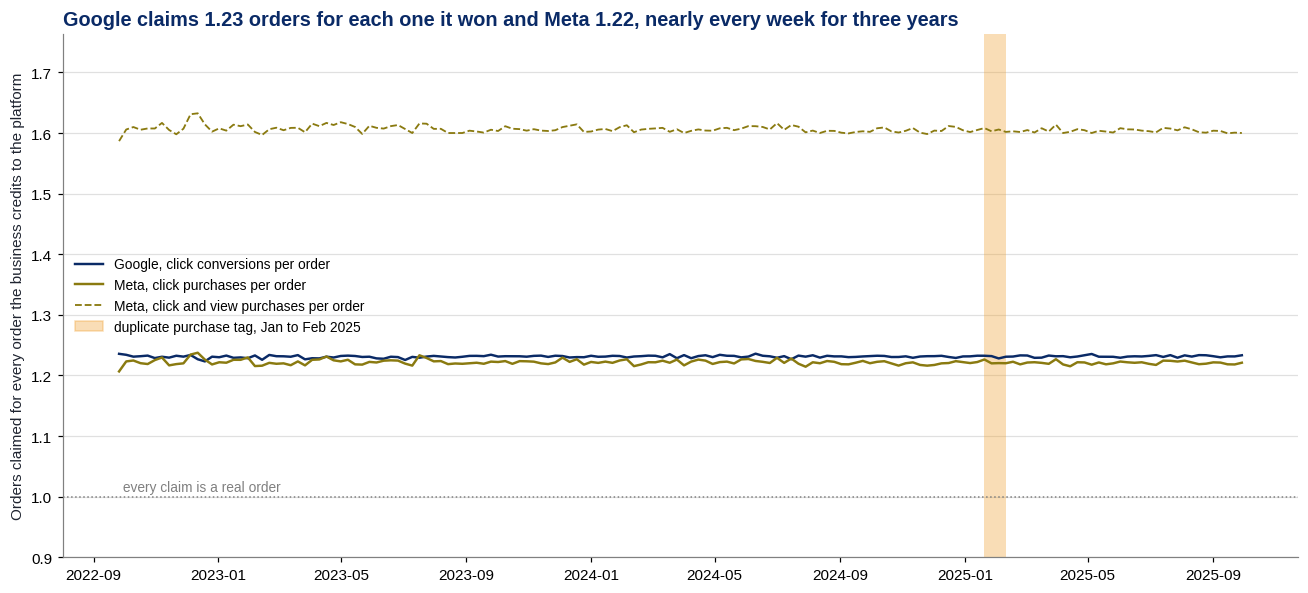

                                                       this notebook        from SQL
flagged weeks above every ordinary week                            0               0   matches


,flagged_weeks_mean,ordinary_weeks_mean,ordinary_lowest,ordinary_highest,flagged_weeks_above_highest,p,verdict
platform,,,,,,,
google,1.231,1.232,1.229,1.235,0,0.683,noise
meta,1.222,1.221,1.215,1.227,0,0.506,noise


In [3]:
# 1. Three years, per platform
tot = (pw.groupby('platform')
         .agg(spend_usd             =('spend_usd', 'sum'),
              claimed_revenue       =('platform_revenue_usd', 'sum'),
              revenue_before_refunds=('revenue_before_refunds_usd', 'sum'),
              net_revenue           =('net_revenue_usd', 'sum'),
              click_claims          =('platform_click_conversions', 'sum'),
              view_claims           =('platform_view_conversions', 'sum'),
              orders                =('orders', 'sum')))
tot.loc['both'] = tot.sum()
tot['platform_roas']          = tot['claimed_revenue'] / tot['spend_usd']
tot['internal_roas']          = tot['net_revenue'] / tot['spend_usd']
tot['claimed_over_actual']    = tot['claimed_revenue'] / tot['net_revenue']
tot['click_claims_per_order'] = tot['click_claims'] / tot['orders']

print(f"{'':<52}{'this notebook':>16}{'from SQL':>16}")
check('platform ROAS, both platforms',            tot.loc['both', 'platform_roas'],         5.66, '{:.2f}', 2)
check('internal ROAS after refunds, both',        tot.loc['both', 'internal_roas'],         4.70, '{:.2f}', 2)
check('claimed over actual, Google',              tot.loc['google', 'claimed_over_actual'], 1.178, '{:.3f}', 3)
check('claimed over actual, Meta',                tot.loc['meta', 'claimed_over_actual'],   1.254, '{:.3f}', 3)
show(tot, money=['spend_usd', 'claimed_revenue', 'revenue_before_refunds', 'net_revenue'],
     ints=['click_claims', 'view_claims', 'orders'],
     dec=['platform_roas', 'internal_roas'], dec3=['claimed_over_actual', 'click_claims_per_order'])

# 2. Claims per order, week by week, for three years
has_orders = pw['orders'] > 0
pw['claims_per_order']     = (pw['platform_click_conversions'] / pw['orders']).where(has_orders)
pw['all_claims_per_order'] = ((pw['platform_click_conversions'] + pw['platform_view_conversions'])
                              / pw['orders']).where(has_orders)
wide = pw.pivot(index='week', columns='platform', values='claims_per_order')
meta_all = pw[pw['platform'] == 'meta'].set_index('week')['all_claims_per_order'].sort_index()
g_med, m_med = wide['google'].median(), wide['meta'].median()

fig, ax = plt.subplots(figsize=(12, 5.5))
for wk in pw.loc[pw['duplicate_event_week'], 'week'].unique():
    ax.axvspan(wk, wk + pd.Timedelta(days=7), color=AMBER, alpha=0.35, linewidth=0)
ax.plot(wide.index, wide['google'], color=NAVY, linewidth=1.6, label='Google, click conversions per order')
ax.plot(wide.index, wide['meta'], color=OLIVE, linewidth=1.6, label='Meta, click purchases per order')
ax.plot(meta_all.index, meta_all, color=OLIVE, linewidth=1.2, linestyle='--', label='Meta, click and view purchases per order')
ax.axhline(1, color=GREY, linewidth=1, linestyle=':')
ax.text(wide.index.min(), 1.005, ' every claim is a real order', color=GREY, fontsize=9, va='bottom')
ax.set_ylim(0.9, np.nanmax(meta_all.values) * 1.08)
ax.set_ylabel('Orders claimed for every order the business credits to the platform')
ax.grid(axis='y', color='#E0E0E0')
ax.set_axisbelow(True)
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles=handles + [Patch(color=AMBER, alpha=0.35)],
          labels=labels + ['duplicate purchase tag, Jan to Feb 2025'], frameon=False, loc='center left', fontsize=9)
ax.set_title(f'Google claims {g_med:.2f} orders for each one it won and Meta {m_med:.2f}, '
             f'nearly every week for three years', loc='left')
plt.tight_layout()
plt.show()

# 3. The three flagged weeks against the ordinary weeks of the GA4 year
rows = []
for platform, g in pw[pw['in_reconciliation_period']].groupby('platform'):
    flagged, ordinary = g[g['duplicate_event_week']], g[~g['duplicate_event_week']]
    _, p = stats.ttest_ind(flagged['claims_per_order'], ordinary['claims_per_order'], equal_var=False)
    rows.append({'platform': platform,
                 'flagged_weeks_mean': flagged['claims_per_order'].mean(),
                 'ordinary_weeks_mean': ordinary['claims_per_order'].mean(),
                 'ordinary_lowest': ordinary['claims_per_order'].min(),
                 'ordinary_highest': ordinary['claims_per_order'].max(),
                 'flagged_weeks_above_highest': (flagged['claims_per_order'] > ordinary['claims_per_order'].max()).sum(),
                 'p': fmt_p(p), 'verdict': 'real' if p < 0.05 else 'noise'})
dup_test = pd.DataFrame(rows).set_index('platform')
print(f"{'':<52}{'this notebook':>16}{'from SQL':>16}")
check('flagged weeks above every ordinary week', dup_test['flagged_weeks_above_highest'].sum(), 0)
show(dup_test, dec3=['flagged_weeks_mean', 'ordinary_weeks_mean', 'ordinary_lowest', 'ordinary_highest'],
     ints=['flagged_weeks_above_highest'])

**Insight and business takeaway:**

Over three years the platforms claimed \$7,055,842 of revenue against \$5,856,811 of net revenue after refunds for the same paid channels: a platform ROAS of 5.66 against an internal ROAS of 4.70. Google claims 7.31 to the order system's 6.20, and Meta 4.08 to 3.25.

The chart shows how they get there: a fixed multiple, week after week. Google reports 1.23 click conversions for every paid order the order system credits to it, and Meta 1.22 click purchases, about 1.6 once its view through purchases are added. Across the 48 ordinary weeks of the GA4 year Google never left 1.229 to 1.235 and Meta 1.215 to 1.227. A gap this steady is how the platforms count, not something that broke.

The duplicate purchases in January and February do not look like they reached the platforms. The three flagged weeks average 1.231 claims per order for Google against 1.232 in ordinary weeks (p = 0.683), and 1.222 against 1.221 for Meta (p = 0.506), and none sits above the ordinary range. So the waterfall's duplicate step, which counts only a flagged week above every ordinary one, is zero.

**Indication:** because the over-claim is so steady, a sudden move in claims per order is the thing worth watching. It belongs in the weekly data health check beside GA4's capture rate.

**Step 2.2: The waterfall, from claimed orders down to real ones**

The walk covers the 51 complete weeks of the GA4 year (7 October 2024 to 28 September 2025), because three of its steps need GA4. It starts from everything Google and Meta claim and takes away, in order:

| Step | What it removes | How it is sized |
| --- | --- | --- |
| Meta view through | Purchases by people who saw a Meta ad and never clicked | Meta's own view through column. Meta puts no value on them, so they are valued at its claimed value per click purchase |
| Duplicate purchase events | Claims added by the purchases GA4 recorded twice, if the platforms saw them too | In a flagged week above every ordinary week, the claims above the platform's median claims per order. Step 2.1 found no such week |
| Double counting | Orders one platform claims that the other platform won by last click | Part of the over-claim, below |
| Attribution window | Orders a platform claims that came back through an unpaid channel inside its click window | Part of the over-claim, below |
| Not explained | Claims beyond anything the click windows allow | Whatever the journeys cannot cover |

The over-claim is what each platform reported beyond the paid orders that happened, once views and duplicates are out. It is taken from the platforms' own figures, never from the journeys. What the journeys add is the split. Google is taken to count an order after a click in the 30 days before it and Meta after a click in the last 7 (the data does not hold the accounts' settings), and neither can see the other or an order that came back through email. So the journeys show how many orders each platform's window would let it claim on top of its own, split between orders the other platform won and orders an unpaid channel won. That room is measured on the orders GA4 saw and scaled up to all orders. The over-claim is divided in the room's proportions, and only an over-claim bigger than the room would leave anything unexplained.

Refunds come last. They take dollars away but not orders, because a refunded order still happened. The walk in orders stops at the paid orders bar; the walk in dollars carries on to net revenue after refunds.

                                                       this notebook        from SQL
platform leg, claims less every step                        15,280.0        15,280.0   matches
platform leg in dollars, down to net revenue           $2,364,481.82   $2,364,481.82   matches
GA4 leg ends on the paid orders                               15,280          15,280   matches
paid orders, 51 weeks                                         15,280          15,280   matches
net revenue after refunds, 51 weeks                    $2,364,481.82   $2,364,481.82   matches
claimed by the platforms, clicks and views                  21,100.6        21,100.6   matches
paid net revenue, channel_daily, same weeks            $2,364,481.82   $2,364,481.82   matches


,step,google_orders,meta_orders,total_orders,google_usd,meta_usd,total_usd
step_number,,,,,,,
1,"Claimed by the platforms, clicks and views","11,267.1","9,833.5","21,100.6","$1,738,704.67","$1,464,597.76","$3,203,302.43"
2,Meta view through purchases,0.0,"-2,350.2","-2,350.2",$0.00,"-$350,037.90","-$350,037.90"
3,"Claimed by the platforms, clicks only","11,267.1","7,483.3","18,750.4","$1,738,704.67","$1,114,559.86","$2,853,264.53"
4,"Duplicate purchase events, January and February",0.0,0.0,0.0,$0.00,$0.00,$0.00
5,Double counting across Google and Meta,-308.3,-492.6,-800.9,"-$31,412.72","-$70,345.90","-$101,758.62"
6,"Attribution window, orders another channel won","-1,809.8",-859.7,"-2,669.5","-$182,112.56","-$130,640.17","-$312,752.73"
7,Not explained by the journeys,0.0,0.0,0.0,$0.00,$0.00,$0.00
8,"Paid orders that happened, last click","9,149.0","6,131.0","15,280.0","$1,525,179.39","$913,573.79","$2,438,753.18"
9,Refunds the platforms never subtract,,,,"-$51,309.53","-$22,961.83","-$74,271.36"


,own_orders,over_claim,room_other_platform,room_unpaid_channels,over_claim_pct,share_of_room_taken
Google,"9,149.0","2,118.1",679.1,"3,987.0",23.2%,45.4%
Meta,"6,131.0","1,352.3","1,109.5","1,936.1",22.1%,44.4%


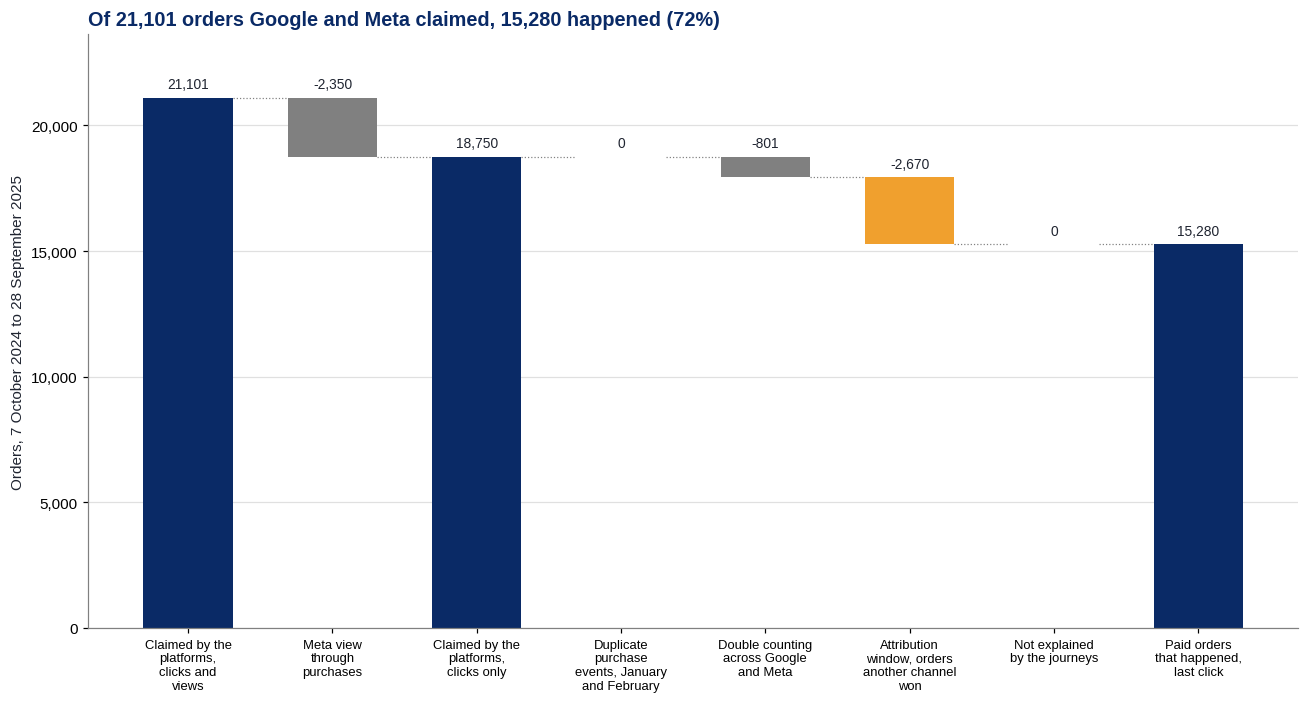

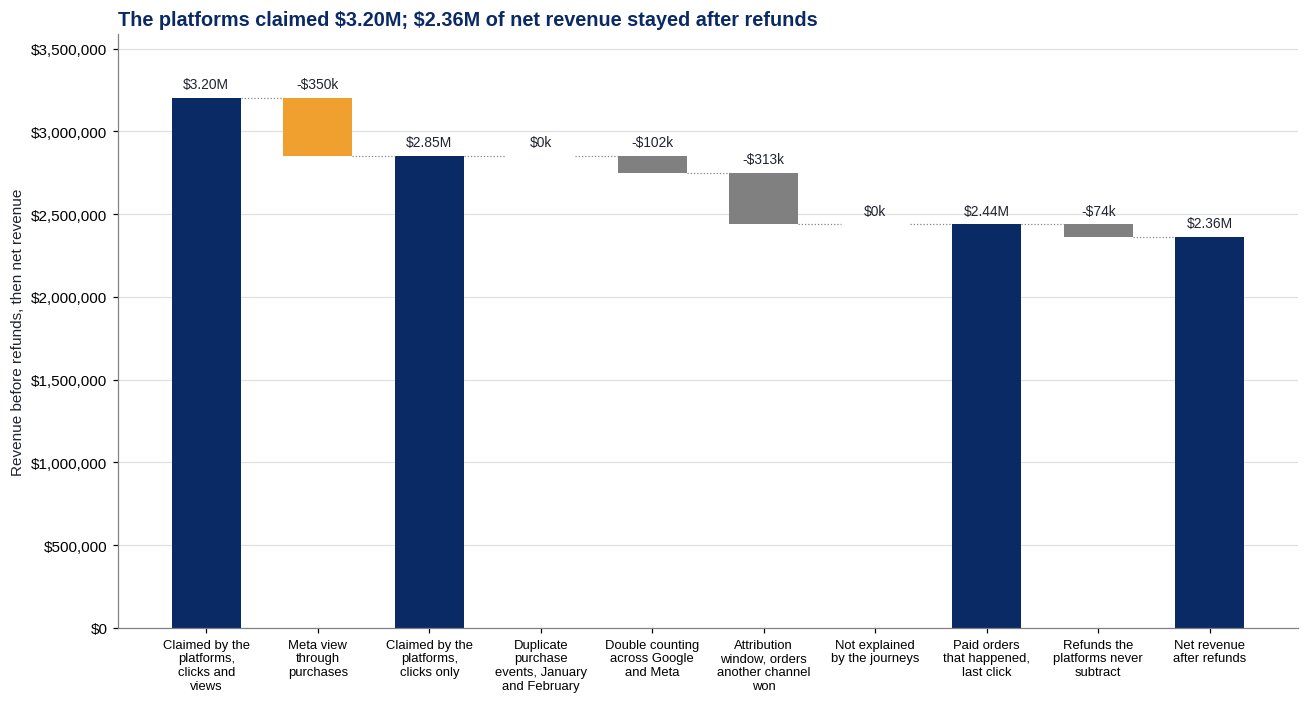

In [4]:
# 1. The 51 weeks, and each platform's usual claims per order from the 48 ordinary ones
period = pw[pw['in_reconciliation_period']].copy()
normal = (period[~period['duplicate_event_week']].groupby('platform')['claims_per_order']
          .agg(['median', 'max']))
po = oj[(oj['order_week'] >= '2024-10-07') & (oj['order_week'] <= '2025-09-22')]
scale = len(po) / po['has_journey'].sum()

# 2. Every figure the walk needs, per platform
def split(over, dmax, wmax):
    """Divide an over-claim between double counting and window in the room's proportions.
    Only an over-claim bigger than the whole room leaves a remainder."""
    if over <= 0:
        return 0.0, 0.0, over
    if over >= dmax + wmax:
        return dmax, wmax, over - dmax - wmax
    return over * dmax / (dmax + wmax), over * wmax / (dmax + wmax), 0.0

P = ['google', 'meta']
f = {}
for p, other in [('google', 'meta'), ('meta', 'google')]:
    w = period[period['platform'] == p]
    flagged = w[w['duplicate_event_week']]
    dup = w['duplicate_event_week'] & (w['claims_per_order'] > normal.loc[p, 'max'])
    click, click_usd = w['platform_click_conversions'].sum(), w['platform_revenue_usd'].sum()
    x = {'claimed_click': click, 'claimed_click_usd': click_usd,
         'view_through': w['platform_view_conversions'].sum(),
         'duplicate_excess': (w['platform_click_conversions'] - normal.loc[p, 'median'] * w['orders'])[dup].sum(),
         'orders': w['orders'].sum(), 'revenue': w['revenue_before_refunds_usd'].sum(),
         'refunded': w['refunded_usd'].sum(), 'net_revenue': w['net_revenue_usd'].sum()}
    x['view_through_usd'] = x['view_through'] * click_usd / click
    x['duplicate_usd'] = x['duplicate_excess'] * (flagged['platform_revenue_usd'].sum()
                                                  / flagged['platform_click_conversions'].sum())
    # the room each click window leaves, on orders GA4 saw, scaled to all orders
    in_window = po['has_journey'] & po['google_click_30d' if p == 'google' else 'meta_click_7d']
    to_other, to_unpaid = in_window & (po['ad_platform'] == other), in_window & po['ad_platform'].isna()
    x['double_max'], x['window_max'] = to_other.sum() * scale, to_unpaid.sum() * scale
    x['double_max_usd'] = po.loc[to_other, 'revenue_before_refunds_usd'].sum() * scale
    x['window_max_usd'] = po.loc[to_unpaid, 'revenue_before_refunds_usd'].sum() * scale
    # the GA4 leg, on the platform's own paid orders
    own = po['ad_platform'] == p
    x['ga4_events'] = po.loc[own, 'ga4_purchase_events'].sum()
    x['ga4_events_usd'] = (po['ga4_purchase_events'] * po['revenue_before_refunds_usd'])[own].sum()
    x['ga4_orders'] = (own & po['seen_in_ga4']).sum()
    x['ga4_orders_usd'] = po.loc[own & po['seen_in_ga4'], 'revenue_before_refunds_usd'].sum()
    # the over-claim, split in the room's proportions
    x['over_claim']     = click - x['duplicate_excess'] - x['orders']
    x['over_claim_usd'] = click_usd - x['duplicate_usd'] - x['revenue']
    x['double'], x['window'], x['unexplained'] = split(x['over_claim'], x['double_max'], x['window_max'])
    x['double_usd'], x['window_usd'], x['unexplained_usd'] = split(x['over_claim_usd'], x['double_max_usd'],
                                                                   x['window_max_usd'])
    f[p] = x
f = pd.DataFrame(f)

# 3. The two legs as one table, a row per step, signs built in
v = lambda name, sign=1: {p: sign * f.loc[name, p] for p in P}
rows = [
    ('platform', 1, 'Claimed by the platforms, clicks and views', 'total',
     {p: f.loc['claimed_click', p] + f.loc['view_through', p] for p in P},
     {p: f.loc['claimed_click_usd', p] + f.loc['view_through_usd', p] for p in P}, None),
    ('platform', 2, 'Meta view through purchases', 'step', v('view_through', -1), v('view_through_usd', -1), None),
    ('platform', 3, 'Claimed by the platforms, clicks only', 'total', v('claimed_click'), v('claimed_click_usd'), None),
    ('platform', 4, 'Duplicate purchase events, January and February', 'step',
     v('duplicate_excess', -1), v('duplicate_usd', -1), None),
    ('platform', 5, 'Double counting across Google and Meta', 'step', v('double', -1), v('double_usd', -1), 'double_max'),
    ('platform', 6, 'Attribution window, orders another channel won', 'step', v('window', -1), v('window_usd', -1), 'window_max'),
    ('platform', 7, 'Not explained by the journeys', 'step', v('unexplained', -1), v('unexplained_usd', -1), None),
    ('platform', 8, 'Paid orders that happened, last click', 'total', v('orders'), v('revenue'), None),
    ('platform', 9, 'Refunds the platforms never subtract', 'step', {p: np.nan for p in P}, v('refunded', -1), None),
    ('platform', 10, 'Net revenue after refunds', 'total', v('orders'), v('net_revenue'), None),
    ('ga4', 1, 'GA4 purchase events on paid orders', 'total', v('ga4_events'), v('ga4_events_usd'), None),
    ('ga4', 2, 'Duplicate purchase events', 'step', {p: f.loc['ga4_orders', p] - f.loc['ga4_events', p] for p in P},
     {p: f.loc['ga4_orders_usd', p] - f.loc['ga4_events_usd', p] for p in P}, None),
    ('ga4', 3, 'Paid orders GA4 recorded', 'total', v('ga4_orders'), v('ga4_orders_usd'), None),
    ('ga4', 4, 'GA4 tracking loss', 'step', {p: f.loc['orders', p] - f.loc['ga4_orders', p] for p in P},
     {p: f.loc['revenue', p] - f.loc['ga4_orders_usd', p] for p in P}, None),
    ('ga4', 5, 'Paid orders that happened, last click', 'total', v('orders'), v('revenue'), None),
]
wf = pd.DataFrame([{'leg': leg, 'step_number': n, 'step': name, 'kind': kind,
                    **{f'{p}_orders': o[p] for p in P}, **{f'{p}_usd': u[p] for p in P},
                    **{f'{p}_journey_max_orders': (np.nan if room is None else f.loc[room, p]) for p in P}}
                   for leg, n, name, kind, o, u, room in rows])
wf['total_orders'] = wf['google_orders'] + wf['meta_orders']
wf['total_usd'] = wf['google_usd'] + wf['meta_usd']
plat = wf[wf['leg'] == 'platform'].set_index('step_number')
ga4  = wf[wf['leg'] == 'ga4'].set_index('step_number')

# 4. Each leg adds up, and the end bar equals the orders recorded in platform_weekly
print(f"{'':<52}{'this notebook':>16}{'from SQL':>16}")
check('platform leg, claims less every step',        plat.loc[1, 'total_orders'] + plat.loc[[2, 4, 5, 6, 7], 'total_orders'].sum(),
      plat.loc[8, 'total_orders'], '{:,.1f}', 1)
check('platform leg in dollars, down to net revenue', plat.loc[1, 'total_usd'] + plat.loc[[2, 4, 5, 6, 7, 9], 'total_usd'].sum(),
      plat.loc[10, 'total_usd'], '${:,.2f}', 2)
check('GA4 leg ends on the paid orders',              ga4.loc[1, 'total_orders'] + ga4.loc[[2, 4], 'total_orders'].sum(),
      ga4.loc[5, 'total_orders'])
check('paid orders, 51 weeks',                        plat.loc[8, 'total_orders'],      15280)
check('net revenue after refunds, 51 weeks',          plat.loc[10, 'total_usd'],        2364481.82, '${:,.2f}', 2)
check('claimed by the platforms, clicks and views',   plat.loc[1, 'total_orders'],      21100.6, '{:,.1f}', 1)
check('paid net revenue, channel_daily, same weeks',  period['net_revenue_usd'].sum(),  plat.loc[10, 'total_usd'], '${:,.2f}', 2)
show(plat[['step', 'google_orders', 'meta_orders', 'total_orders', 'google_usd', 'meta_usd', 'total_usd']],
     dec1=['google_orders', 'meta_orders', 'total_orders'], money=['google_usd', 'meta_usd', 'total_usd'])

# 5. How much of its window's room each platform takes
room = pd.DataFrame({
    'own_orders'          : f.loc['orders'],
    'over_claim'          : f.loc['over_claim'],
    'room_other_platform' : f.loc['double_max'],
    'room_unpaid_channels': f.loc['window_max'],
}).rename(index=str.capitalize)
room['over_claim_pct']      = 100 * room['over_claim'] / room['own_orders']
room['share_of_room_taken'] = 100 * room['over_claim'] / (room['room_other_platform'] + room['room_unpaid_channels'])
show(room, dec1=['own_orders', 'over_claim', 'room_other_platform', 'room_unpaid_channels'],
     pct=['over_claim_pct', 'share_of_room_taken'])

# 6. The walk in orders, then in dollars
claimed, actual = plat.loc[1, 'total_orders'], plat.loc[8, 'total_orders']
waterfall([(plat.loc[s, 'step'], plat.loc[s, 'total_orders'], plat.loc[s, 'kind']) for s in range(1, 9)],
          title=f'Of {claimed:,.0f} orders Google and Meta claimed, {actual:,.0f} happened ({100 * actual / claimed:.0f}%)',
          ylabel='Orders, 7 October 2024 to 28 September 2025', fmt=lambda v: f'{v:,.0f}', axis_fmt='{x:,.0f}')
claimed_usd, net_usd = plat.loc[1, 'total_usd'], plat.loc[10, 'total_usd']
waterfall([(plat.loc[s, 'step'], plat.loc[s, 'total_usd'], plat.loc[s, 'kind']) for s in range(1, 11)],
          title=f'The platforms claimed {money_short(claimed_usd)}; {money_short(net_usd)} of net revenue stayed after refunds',
          ylabel='Revenue before refunds, then net revenue', fmt=money_short, axis_fmt='${x:,.0f}')

**Insight and business takeaway:**

Both legs add up, and the walk lands on the 15,280 paid orders and \$2,364,481.82 of net revenue that `platform_weekly` records for the same weeks.

Over the 51 weeks Google and Meta claimed 21,101 orders between them, and 15,280 happened, 72 percent. The largest step in orders is the attribution window: 2,670 orders, \$312,753, claimed by a platform but won by an unpaid channel such as email, organic search or direct. Meta's view through purchases are the largest step in dollars, 2,350 orders valued at \$350,038, 24 percent of everything Meta claimed. Double counting between the two platforms takes out 801 orders, \$101,759. Duplicate events are zero. Each platform's over-claim fits inside the room its click window allows, so all of it goes to double counting and the window, and none is left over.

The over-claim looks like real orders, claimed twice. Google's click window, taken as 30 days, would let it claim 4,666 orders beyond the 9,149 it won by last click; it claimed 2,118 more, 45.4 percent of that room. Meta's 7 day window allows 3,046 beyond its 6,131 and it claimed 1,352, 44.4 percent. Every order they over-claim fits inside orders another channel won with that platform's click in the window, and each takes under half of that room.

In dollars, \$3.20M claimed becomes \$2.44M of revenue before refunds, and \$74,271 of refunds the platforms never subtract leaves \$2.36M of net revenue, 74 percent of the claim.

**Indication:** adding Google's and Meta's reports together, or adding either to email and organic search, counts the same orders twice. No Meta figure should leave Meta Ads Manager with view through purchases still in it.

**Step 2.3: The same walk from GA4, and which number to use for which decision**

GA4 sits between the platforms and the order system. It sees the website, so it has no view through problem and no click window, but it has two faults of its own: purchases recorded twice in January and February, and orders it never sees, about 12 percent of them, more in May when two days were lost to an outage. Refused consent and blocked tags are the usual reasons for a gap like that, though the data does not show which. Its leg starts from purchase events on the orders the order system credits to Google and Meta, removes the second events, then adds back the orders GA4 never recorded, and has to land on the same 15,280 paid orders.

Each number answers a different question, and the trouble starts when one is used for another's job:

| Decision | Number to use | Why |
| --- | --- | --- |
| Bids, audiences and creative inside Google Ads or Meta | The platform's own conversions | The bidding systems learn from their own signal, which is consistent from day to day inside one platform |
| Comparing channels, reporting return on spend, setting the budget | Internal ROAS: order system net revenue after refunds, credited by last click | One rule for every channel, no order counted twice, refunds out, and it ties to the finance numbers |
| Funnel, landing pages and behaviour on the site | GA4 | The only source with sessions. Its order counts are short, so they are scaled up or not used as totals |
| Profit and loss, and anything finance signs off | Order system net revenue after refunds | The money that stayed with the business |
| Whether a channel creates sales that would not have happened anyway | None of these | It needs a holdout test; until then, each channel's break even incrementality from the unit economics is the line to argue about |

The cell puts a figure on the first four, for the same 51 weeks and the same spend.

                                                       this notebook        from SQL
duplicate purchase events on paid orders                         248             248   matches
capture rate, paid orders                                      0.881           0.881   matches
capture rate, every order in the GA4 year                      0.881           0.881   matches


,paid_orders,purchase_events,duplicate_events,orders_ga4_saw,capture_rate,lost_orders
Google,"9,149","8,246",154,"8,092",0.884,"1,057"
Meta,"6,131","5,465",94,"5,371",0.876,760
Both,"15,280","13,711",248,"13,463",0.881,"1,817"


Capture rate, Google against Meta: +0.84 points, z = 1.58, p = 0.115, noise



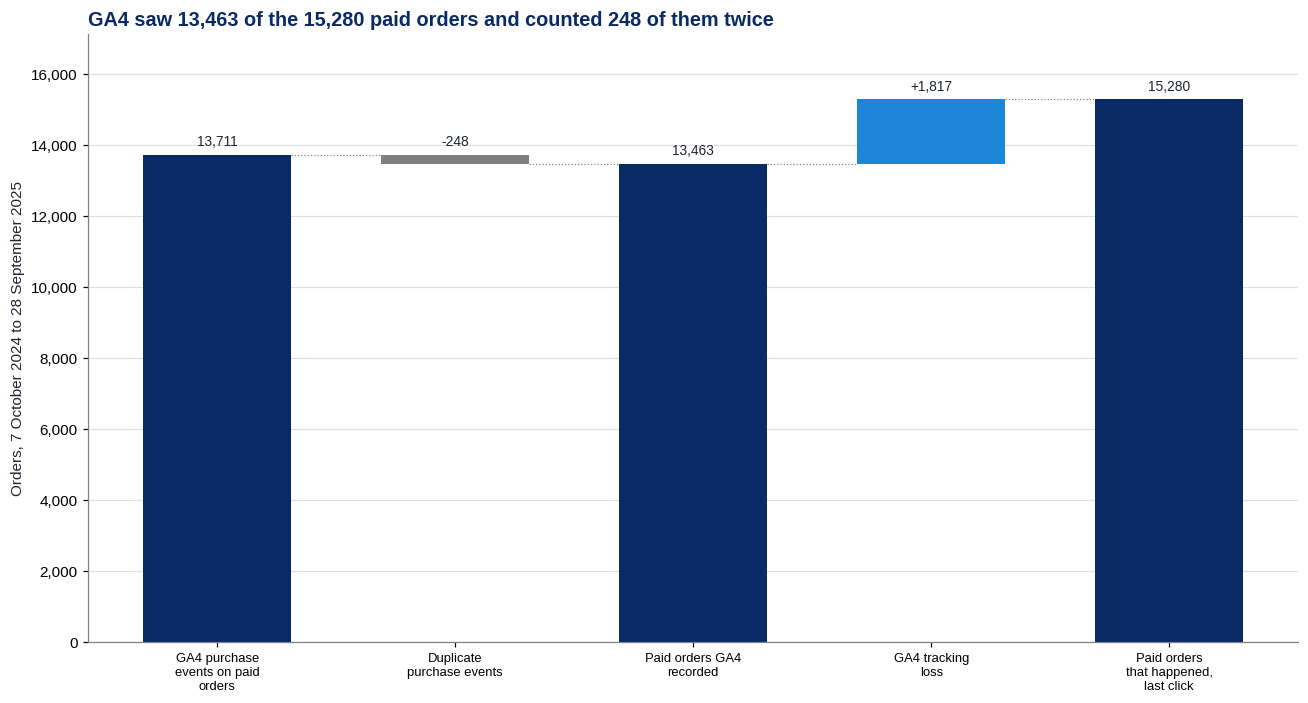

spend in the 51 weeks                                    $489,212.69     $489,212.69   matches

The same paid orders and spend, as return on ad spend


,"platform, clicks and views",platform reported,GA4 recorded,"order system, before refunds","net revenue, after refunds"
Google,7.43,7.43,5.74,6.52,6.30
Meta,5.74,4.37,3.15,3.58,3.49
Both,6.55,5.83,4.39,4.99,4.83


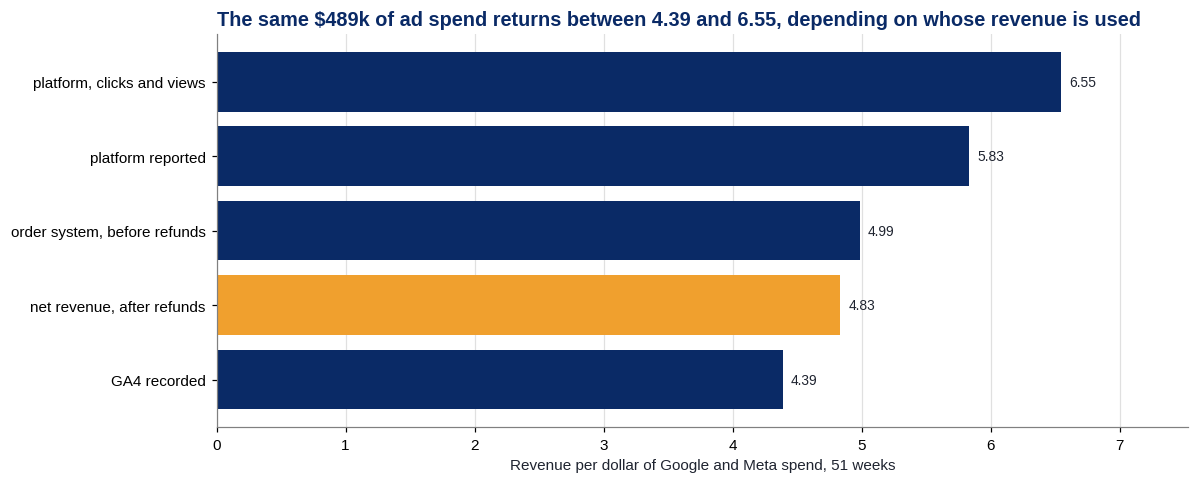

In [5]:
# 1. Capture rate by platform, and whether GA4 loses more of one than the other
cap = pd.DataFrame({
    'paid_orders'     : plat.loc[8, ['google_orders', 'meta_orders']].values,
    'purchase_events' : ga4.loc[1, ['google_orders', 'meta_orders']].values,
    'duplicate_events': -ga4.loc[2, ['google_orders', 'meta_orders']].values,
    'orders_ga4_saw'  : ga4.loc[3, ['google_orders', 'meta_orders']].values,
}, index=['Google', 'Meta']).astype(float)
cap.loc['Both'] = cap.sum()
cap['capture_rate'] = cap['orders_ga4_saw'] / cap['paid_orders']
cap['lost_orders']  = cap['paid_orders'] - cap['orders_ga4_saw']
z, p_cap = proportions_ztest(cap.loc[['Google', 'Meta'], 'orders_ga4_saw'], cap.loc[['Google', 'Meta'], 'paid_orders'])

print(f"{'':<52}{'this notebook':>16}{'from SQL':>16}")
check('duplicate purchase events on paid orders', cap.loc['Both', 'duplicate_events'], 248)
check('capture rate, paid orders', cap.loc['Both', 'capture_rate'], 0.881, '{:.3f}', 3)
check('capture rate, every order in the GA4 year', oj['seen_in_ga4'].mean(), 0.881, '{:.3f}', 3)
show(cap, ints=['paid_orders', 'purchase_events', 'duplicate_events', 'orders_ga4_saw', 'lost_orders'],
     dec3=['capture_rate'])
gap = 100 * (cap.loc['Google', 'capture_rate'] - cap.loc['Meta', 'capture_rate'])
print(f"Capture rate, Google against Meta: {gap:+.2f} points, z = {z:.2f}, p = {fmt_p(p_cap)}, "
      f"{'real' if p_cap < 0.05 else 'noise'}\n")

waterfall([(ga4.loc[s, 'step'], ga4.loc[s, 'total_orders'], ga4.loc[s, 'kind']) for s in range(1, 6)],
          title=f"GA4 saw {ga4.loc[3, 'total_orders']:,.0f} of the {ga4.loc[5, 'total_orders']:,.0f} paid orders "
                f"and counted {-ga4.loc[2, 'total_orders']:,.0f} of them twice",
          ylabel='Orders, 7 October 2024 to 28 September 2025', fmt=lambda v: f'{v:,.0f}', axis_fmt='{x:,.0f}')

# 2. Every source's revenue for the same paid orders and the same spend
spend51 = period.groupby('platform')['spend_usd'].sum()
nums = pd.DataFrame({
    'spend'                       : spend51.reindex(P).values,
    'platform, clicks and views'  : plat.loc[1, ['google_usd', 'meta_usd']].values,
    'platform reported'           : plat.loc[3, ['google_usd', 'meta_usd']].values,
    'GA4 recorded'                : ga4.loc[3, ['google_usd', 'meta_usd']].values,
    'order system, before refunds': plat.loc[8, ['google_usd', 'meta_usd']].values,
    'net revenue, after refunds'  : plat.loc[10, ['google_usd', 'meta_usd']].values,
}, index=['Google', 'Meta']).astype(float)
nums.loc['Both'] = nums.sum()
roas = nums.drop(columns='spend').div(nums['spend'], axis=0)
check('spend in the 51 weeks', nums.loc['Both', 'spend'], 489212.69, '${:,.2f}', 2)
print('\nThe same paid orders and spend, as return on ad spend')
show(roas, dec=list(roas.columns))

both = roas.loc['Both']
colours = {k: (AMBER if k == 'net revenue, after refunds' else NAVY) for k in both.index}
hbar(both, lambda v: f'{v:.2f}',
     title=f"The same {money_short(nums.loc['Both', 'spend'])} of ad spend returns between "
           f"{both.min():.2f} and {both.max():.2f}, depending on whose revenue is used",
     xlabel='Revenue per dollar of Google and Meta spend, 51 weeks', colours=colours, legend=False)

**Insight and business takeaway:**

GA4 recorded 13,711 purchase events on the 15,280 paid orders. 248 were second events on the same order, which leaves 13,463 orders GA4 saw. The other 1,817, 11.9 percent, it never saw. Capture rate is 0.881 on paid orders, the same as for every order in the year, and the 0.84 point gap between Google (0.884) and Meta (0.876) is noise (z = 1.58, p = 0.115).

The same \$489,213 of spend over 51 weeks returns anything from 4.39 to 6.55 depending on whose revenue is used. With Meta's views the platforms say 6.55; without them 5.83, which is the platform ROAS on the dashboard. The order system says 4.99 before refunds and 4.83 after. GA4 says 4.39, because it never sees about one paid order in eight. Meta's spread is the widest: 5.74 with views, 4.37 without, and 3.49 internal.

**Indication:** GA4 is fair between channels but short on totals, so its order counts need deduplicating and then scaling up by about 1.135 before they sit beside anything finance reports. The budget is built on internal ROAS, 4.83 for these weeks.

<h2 style="color:#0A2A66; border-bottom:2px solid #F0A02E; padding-bottom:6px; margin-top:36px;">Section 3: Attribution</h2>

**Step 3.1: Journeys, and orders credited under four rules**

A journey is every session the same person had in the 30 days up to and including the session they bought in. In a one session journey every rule gives the whole order to the same channel, so only the longer ones can move any credit. Two checks come first: whether GA4's last click (the channel of the session they bought in) agrees with the order system's, and where it does not, whether the disagreement stays inside one platform.

The same 27,905 journeys are then scored four ways:

| Rule | Who gets the credit |
| --- | --- |
| Last click | The session they bought in. How the business credits orders today |
| First click | The first session in the 30 days |
| Linear | Every session an equal share |
| Position based | 40 percent to the first session, 40 to the last, the remaining 20 split across the middle |

Each rule hands out exactly one order per journey. A channel that gains under first click is opening journeys someone else closes; one that loses is mostly closing journeys someone else opened.

                                                       this notebook        from SQL
single session journeys                                       12,886          12,886   matches
GA4 session channel equals the order channel                  27,343          27,343   matches
orders where they disagree on the platform                         0               0   matches
orders credited, last click                                27,905.00       27,905.00   matches
orders credited, first click                               27,905.00       27,905.00   matches
orders credited, linear                                    27,905.00       27,905.00   matches
orders credited, position based                            27,905.00       27,905.00   matches


,orders,share_pct
sessions in journey,,
1,"12,886",46.2%
2,"7,585",27.2%
3,"6,455",23.1%
4,953,3.4%
5 or more,26,0.1%


Journeys of two or more sessions began a median of 7.7 days before the order (a quarter more than 12.0 days before).



,Last click,First click,Linear,Position based,first_vs_last_pct,position_vs_last_pct
touch_channel,,,,,,
Organic Search,"4,550.00","6,735.00","5,831.24","5,747.66",48.0%,26.3%
Google Non Brand,"3,562.00","5,493.00","4,704.87","4,628.04",54.2%,29.9%
Meta Prospecting,"3,472.00","6,290.00","5,122.87","5,016.65",81.2%,44.5%
Email,"3,308.00","2,313.00","2,718.31","2,760.56",-30.1%,-16.5%
Direct,"2,843.00","1,076.00","1,808.23","1,874.14",-62.2%,-34.1%
Google Brand,"2,499.00",654.00,"1,416.63","1,485.36",-73.8%,-40.6%
Google Shopping,"2,021.00","1,225.00","1,558.73","1,586.53",-39.4%,-21.5%
Meta Retargeting,"1,887.00",233.00,915.87,978.90,-87.7%,-48.1%
Affiliate Coupon,"1,609.00",339.00,857.02,908.65,-78.9%,-43.5%


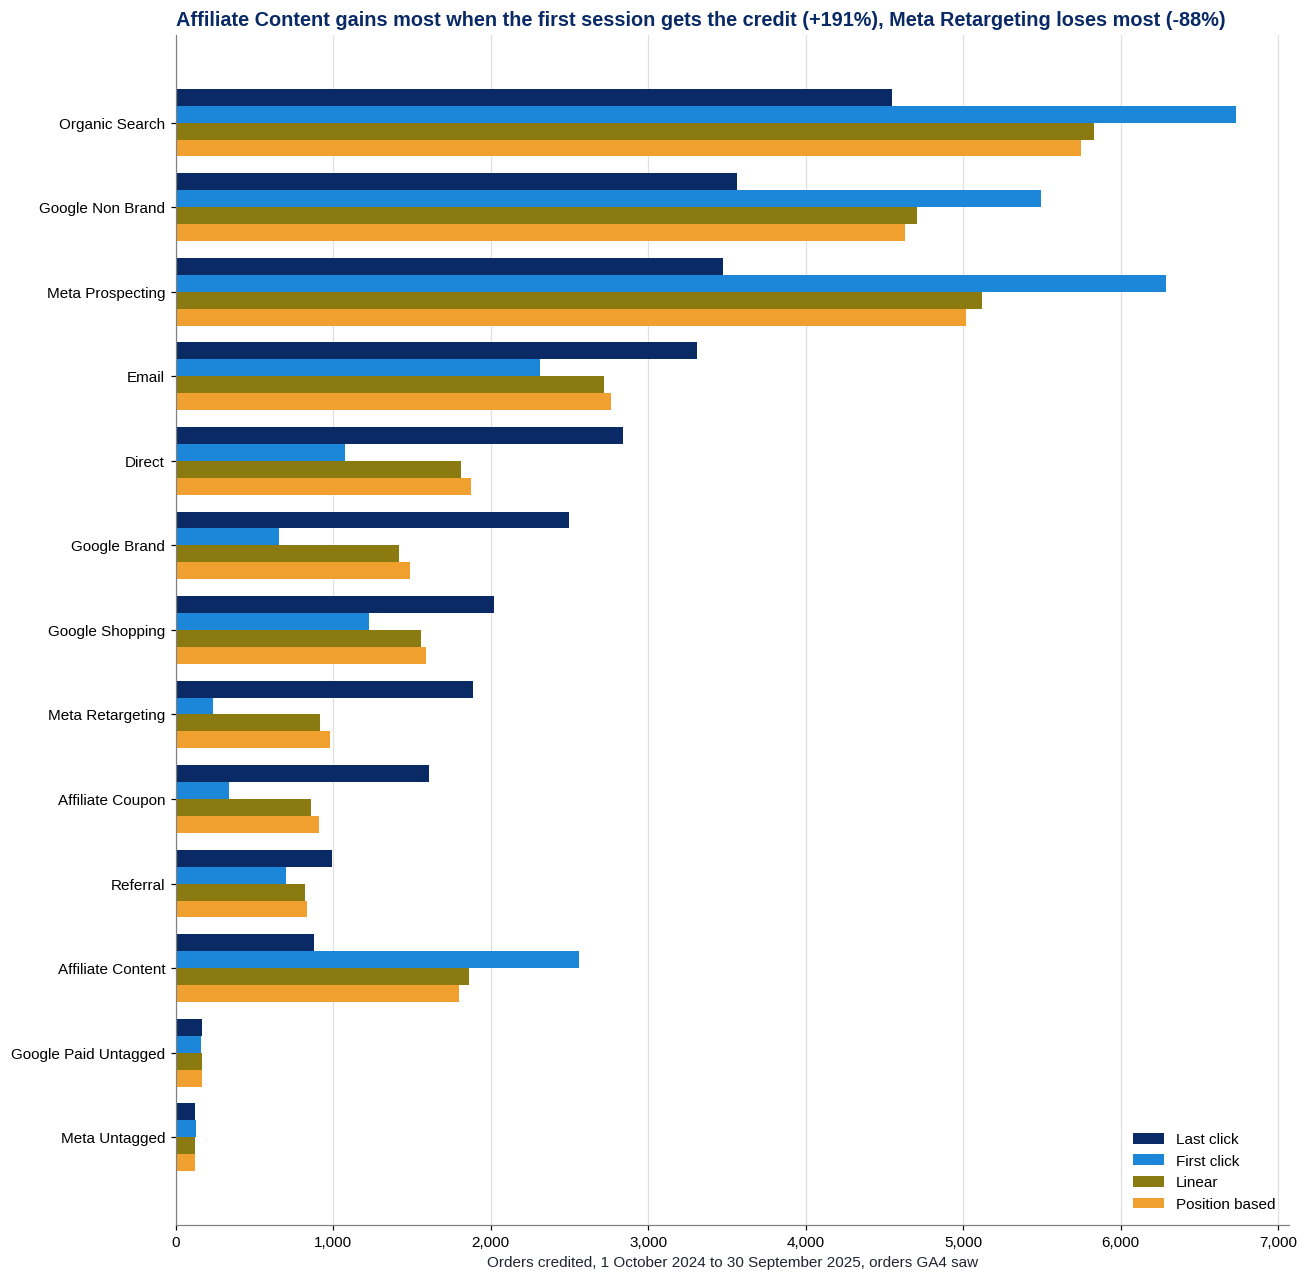

In [6]:
# 1. How long the journeys are, and when the longer ones began
j = oj[oj['has_journey']].copy()
lengths = j['touches_in_journey'].clip(upper=5).map(lambda n: '5 or more' if n == 5 else f'{n:.0f}')
dist = lengths.value_counts().sort_index().rename('orders').to_frame()
dist['share_pct'] = 100 * dist['orders'] / len(j)
dist.index.name = 'sessions in journey'
starts = jt[(jt['touch_number'] == 1) & (jt['touches_in_journey'] > 1)]['days_before_order']

# 2. GA4's last click against the order system's
conv = jt[jt['is_converting_session']]
same_channel = conv['touch_channel'] == conv['order_channel']
same_family  = conv['touch_channel'].map(FAMILY) == conv['order_channel'].map(FAMILY)

# 3. Credit by channel under each rule
RULES = {'credit_last_click': 'Last click', 'credit_first_click': 'First click',
         'credit_linear': 'Linear', 'credit_position_based': 'Position based'}
cred = jt.groupby('touch_channel')[list(RULES)].sum().rename(columns=RULES)
cred.index = cred.index.map(LABEL)
cred = cred.sort_values('Last click', ascending=False)
cred['first_vs_last_pct']    = 100 * (cred['First click'] / cred['Last click'] - 1)
cred['position_vs_last_pct'] = 100 * (cred['Position based'] / cred['Last click'] - 1)

print(f"{'':<52}{'this notebook':>16}{'from SQL':>16}")
check('single session journeys', (j['touches_in_journey'] == 1).sum(), 12886)
check('GA4 session channel equals the order channel', same_channel.sum(), 27343)
check('orders where they disagree on the platform', (~same_family).sum(), 0)
for r in RULES.values():
    check(f'orders credited, {r.lower()}', cred[r].sum(), 27905, '{:,.2f}', 2)
show(dist, ints=['orders'], pct=['share_pct'])
print(f'Journeys of two or more sessions began a median of {starts.median():.1f} days before the order '
      f'(a quarter more than {starts.quantile(0.75):.1f} days before).\n')
show(cred, dec=list(RULES.values()), pct=['first_vs_last_pct', 'position_vs_last_pct'])

# 4. Four bars per channel, biggest last click channel at the top
order = cred.index[::-1]
y, h = np.arange(len(order)), 0.2
rule_colours = {'Last click': NAVY, 'First click': BLUE, 'Linear': OLIVE, 'Position based': AMBER}
fig, ax = plt.subplots(figsize=(12, 0.75 * len(order) + 2))
for k, (r, c) in enumerate(rule_colours.items()):
    ax.barh(y + (1.5 - k) * h, cred.loc[order, r], height=h, color=c, label=r)
ax.set_yticks(y)
ax.set_yticklabels(order)
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))
ax.set_xlabel('Orders credited, 1 October 2024 to 30 September 2025, orders GA4 saw')
ax.grid(axis='x', color='#E0E0E0')
ax.set_axisbelow(True)
ax.legend(frameon=False, loc='lower right')
gainer, loser = cred['first_vs_last_pct'].idxmax(), cred['first_vs_last_pct'].idxmin()
ax.set_title(f"{gainer} gains most when the first session gets the credit "
             f"({cred.loc[gainer, 'first_vs_last_pct']:+.0f}%), {loser} loses most "
             f"({cred.loc[loser, 'first_vs_last_pct']:+.0f}%)", loc='left')
plt.tight_layout()
plt.show()

**Insight and business takeaway:**

46.2 percent of the orders GA4 saw came from a single session, so every rule gives those to the same channel. 27.2 percent took two sessions and 23.1 percent three, and the longer journeys began a median of 7.7 days before the order. GA4's last click agrees with the order system on 27,343 of the 27,905 orders, and every disagreement stays inside one platform: a tagged campaign on one side and the untagged bucket on the other.

The channels split into openers and closers. Under first click Affiliate Content almost triples, from 880 orders to 2,560 (+190.9 percent), Meta Prospecting goes from 3,472 to 6,290 (+81.2 percent), Google Non Brand gains 54.2 percent and Organic Search 48.0 percent. Meta Retargeting falls from 1,887 to 233 (-87.7 percent), Affiliate Coupon loses 78.9 percent, Google Brand 73.8 percent and Direct 62.2 percent. Position based lands about halfway, because it still gives 40 percent to the last session: Affiliate Content +104.5 percent, Google Brand -40.6 and Meta Retargeting -48.1. Linear and position based give almost the same answer on journeys this short.

**Indication:** last click hands the credit to the channels that finish journeys: retargeting, coupon sites, brand search and direct. The channels that start them, content partners, Meta Prospecting and non brand search, get more credit under every other rule than last click gives them.

**Step 3.2: Is the movement beyond noise?**

A shift of a few dozen orders between rules could be chance: which journeys happened to fall in this particular year. The bootstrap asks how much each shift would wobble if the year had been drawn again. It resamples the 27,905 orders with replacement 400 times, recomputes every channel's change from last click under each rule, and takes the middle 95 percent of the results as the interval. A change whose interval includes zero is noise. Resampling whole orders keeps each journey's sessions together, and the random seed is fixed, so the intervals come out the same on every run.

In [7]:
# 1. One row per order, one column per channel, for each rule
mats = {r: jt.pivot_table(index='order_id', columns='touch_channel', values=r, aggfunc='sum', fill_value=0.0)
        for r in RULES}
channels = sorted(set().union(*[m.columns for m in mats.values()]))
mats = {r: m.reindex(columns=channels, fill_value=0.0).sort_index() for r, m in mats.items()}
others = ['credit_first_click', 'credit_linear', 'credit_position_based']
diffs = np.hstack([(mats[r] - mats['credit_last_click']).values for r in others])

# 2. Resample orders 400 times, in blocks of 100 to keep memory down
rng = np.random.default_rng(2025)
n, B = diffs.shape[0], 400
boot = np.vstack([rng.multinomial(n, np.full(n, 1 / n), size=100) @ diffs for _ in range(B // 100)])
lo, hi = np.percentile(boot, [2.5, 97.5], axis=0)

# 3. The change from last click under each rule, with its interval
k = len(channels)
moves = pd.DataFrame([{'channel': LABEL[ch], 'rule': RULES[r], 'change_in_orders': diffs[:, i * k + c].sum(),
                       'ci_low': lo[i * k + c], 'ci_high': hi[i * k + c],
                       'verdict': 'real' if (lo[i * k + c] > 0 or hi[i * k + c] < 0) else 'noise'}
                      for i, r in enumerate(others) for c, ch in enumerate(channels)])

print(f"{'':<52}{'this notebook':>16}{'from SQL':>16}")
check('orders resampled', n, 27905)
check('changes add to zero under every rule', abs(moves.groupby('rule')['change_in_orders'].sum()).max(), 0, '{:,.1f}', 1)
for r in ['First click', 'Linear', 'Position based']:
    sub = moves[moves['rule'] == r].set_index('channel').reindex(cred.index)
    print(f'\n{r} against last click: change in orders credited, 95% bootstrap interval')
    show(sub[['change_in_orders', 'ci_low', 'ci_high', 'verdict']], dec1=['change_in_orders', 'ci_low', 'ci_high'])
print('\nChannels whose credit moves beyond noise:')
print(moves[moves['verdict'] == 'real'].groupby('rule').size()
      .reindex(['First click', 'Linear', 'Position based']).fillna(0).astype(int).to_string())

                                                       this notebook        from SQL
orders resampled                                              27,905          27,905   matches
changes add to zero under every rule                             0.0             0.0   matches

First click against last click: change in orders credited, 95% bootstrap interval


,change_in_orders,ci_low,ci_high,verdict
touch_channel,,,,
Organic Search,"2,185.0","2,030.0","2,328.1",real
Google Non Brand,"1,931.0","1,804.9","2,056.1",real
Meta Prospecting,"2,818.0","2,699.0","2,945.0",real
Email,-995.0,"-1,114.0",-897.0,real
Direct,"-1,767.0","-1,854.0","-1,682.0",real
Google Brand,"-1,845.0","-1,928.0","-1,754.0",real
Google Shopping,-796.0,-849.0,-746.0,real
Meta Retargeting,"-1,654.0","-1,741.0","-1,577.0",real
Affiliate Coupon,"-1,270.0","-1,342.0","-1,205.0",real



Linear against last click: change in orders credited, 95% bootstrap interval


,change_in_orders,ci_low,ci_high,verdict
touch_channel,,,,
Organic Search,"1,281.2","1,197.2","1,361.5",real
Google Non Brand,"1,142.9","1,077.2","1,215.8",real
Meta Prospecting,"1,650.9","1,589.0","1,718.5",real
Email,-589.7,-657.3,-532.9,real
Direct,"-1,034.8","-1,085.6",-985.5,real
Google Brand,"-1,082.4","-1,135.2","-1,027.8",real
Google Shopping,-462.3,-493.9,-432.2,real
Meta Retargeting,-971.1,"-1,022.4",-923.8,real
Affiliate Coupon,-752.0,-795.1,-714.1,real



Position based against last click: change in orders credited, 95% bootstrap interval


,change_in_orders,ci_low,ci_high,verdict
touch_channel,,,,
Organic Search,"1,197.7","1,119.1","1,271.7",real
Google Non Brand,"1,066.0","1,001.6","1,129.0",real
Meta Prospecting,"1,544.7","1,487.9","1,609.4",real
Email,-547.4,-610.5,-496.7,real
Direct,-968.9,"-1,015.5",-922.5,real
Google Brand,"-1,013.6","-1,062.2",-963.5,real
Google Shopping,-434.5,-463.2,-406.9,real
Meta Retargeting,-908.1,-955.5,-865.4,real
Affiliate Coupon,-700.4,-742.1,-663.9,real



Channels whose credit moves beyond noise:
rule
First click       11
Linear            11
Position based    11


**Insight and business takeaway:**

Under every rule, 11 of the 13 channels move beyond noise, and the intervals are narrow next to the shifts. Meta Prospecting gains 2,818 orders under first click, with an interval of 2,699 to 2,945; Google Brand loses 1,845, between 1,754 and 1,928. The intervals come from redrawing this one year's orders, so they show the shifts are not luck in which orders happened to be in the sample; they cannot say whether another year would look the same. The two untagged buckets are noise under all three rules: Google Paid Untagged moves by -6 orders under first click, with an interval of -30 to +18.

**Indication:** the gap between rules is real, so choosing a rule is a business decision, not a statistical one. No rule proves which channel caused an order; that takes an experiment. The rules show how wide the range of reasonable answers is.

**Step 3.3: What the rules do to revenue, profit and return on spend**

Channel decisions in this project are judged on gross profit, so the first table gives net revenue after refunds and gross profit credited to each channel under each rule, on the orders GA4 saw. Each rule's column adds to the same total, because the rules only move credit around.

The second table turns that into return on spend for the five paid channels with campaigns. Journeys only cover the orders GA4 saw, so each rule's revenue is taken as a multiple of last click revenue on the same journeys, and that multiple is applied to the channel's full last click net revenue from `channel_daily` over the same year. That assumes the orders GA4 missed would split between the rules like the ones it saw, which fits a capture rate that hardly differs by platform.

                                                       this notebook        from SQL
net revenue credited, last click                          $4,442,205      $4,442,205   matches
net revenue credited, first click                         $4,442,205      $4,442,205   matches
net revenue credited, linear                              $4,442,205      $4,442,205   matches
net revenue credited, position based                      $4,442,205      $4,442,205   matches
gross profit credited, last click                         $2,771,238      $2,771,238   matches
gross profit credited, first click                        $2,771,238      $2,771,238   matches
gross profit credited, linear                             $2,771,238      $2,771,238   matches
gross profit credited, position based                     $2,771,238      $2,771,238   matches

Gross profit credited, orders GA4 saw


,Last click,First click,Linear,Position based
touch_channel,,,,
Organic Search,"$466,928.66","$676,733.65","$586,794.31","$580,288.83"
Google Non Brand,"$364,376.38","$559,473.45","$481,279.86","$472,747.33"
Meta Prospecting,"$315,061.17","$610,929.85","$490,302.83","$478,299.32"
Email,"$349,321.43","$240,661.16","$285,158.96","$289,646.13"
Direct,"$295,844.14","$106,805.82","$184,764.92","$191,984.21"
Google Brand,"$255,968.88","$60,797.43","$141,930.00","$148,994.56"
Google Shopping,"$192,261.12","$112,932.60","$146,046.75","$148,877.76"
Meta Retargeting,"$189,059.01","$21,919.67","$90,964.81","$97,313.52"
Affiliate Coupon,"$133,836.52","$27,492.83","$70,948.55","$75,205.51"


Google Brand ROAS, last click                                  14.80           14.80   matches


,spend,net_revenue_last_click,gross_profit_last_click,"ROAS, last click","ROAS, first click","ROAS, linear","ROAS, position based","GP per $ spend, last click","GP per $ spend, position based"
channel,,,,,,,,,
Google Brand,"$31,289.45","$463,062.47","$289,393.07",14.80,3.61,8.26,8.66,9.25,5.38
Google Non Brand,"$127,143.68","$665,377.37","$414,226.03",5.23,8.01,6.89,6.77,3.26,4.23
Google Shopping,"$80,300.48","$345,409.19","$217,829.57",4.30,2.53,3.27,3.34,2.71,2.10
Meta Prospecting,"$205,487.28","$549,909.79","$359,610.65",2.68,5.33,4.25,4.14,1.75,2.66
Meta Retargeting,"$54,727.02","$336,044.12","$212,515.43",6.14,0.69,2.94,3.15,3.88,2.00


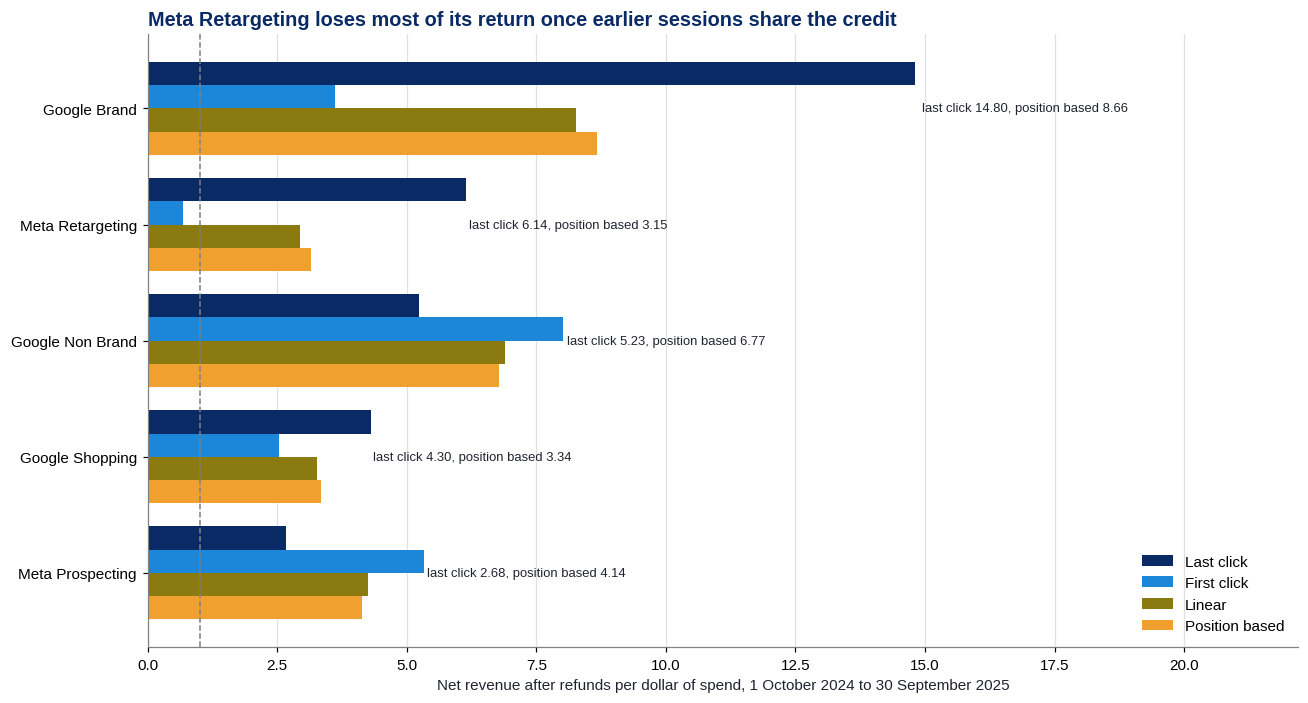

In [8]:
# 1. Net revenue after refunds and gross profit under each rule
rev = jt[list(RULES)].mul(jt['net_revenue_after_refund_usd'], axis=0).groupby(jt['touch_channel']).sum()
gpr = jt[list(RULES)].mul(jt['gross_profit_usd'], axis=0).groupby(jt['touch_channel']).sum()
print(f"{'':<52}{'this notebook':>16}{'from SQL':>16}")
for r, name in RULES.items():
    check(f'net revenue credited, {name.lower()}', rev[r].sum(), 4442205, '${:,.0f}')
for r, name in RULES.items():
    check(f'gross profit credited, {name.lower()}', gpr[r].sum(), 2771238, '${:,.0f}')
print('\nGross profit credited, orders GA4 saw')
show(gpr.rename(columns=RULES, index=LABEL).reindex(cred.index), money=list(RULES.values()))

# 2. Return on spend for the five tagged paid channels, GA4 year
PAID = ['google_brand', 'google_nonbrand', 'google_shopping', 'meta_prospecting', 'meta_retargeting']
mult  = rev.loc[PAID].div(rev.loc[PAID, 'credit_last_click'], axis=0)
gmult = gpr.loc[PAID].div(gpr.loc[PAID, 'credit_last_click'], axis=0)
ret = pd.DataFrame({'spend': cd.loc[PAID, 'spend_usd'],
                    'net_revenue_last_click': cd.loc[PAID, 'net_revenue_usd'],
                    'gross_profit_last_click': cd.loc[PAID, 'gross_profit_usd']})
for r, name in RULES.items():
    ret[f'ROAS, {name.lower()}'] = ret['net_revenue_last_click'] * mult[r] / ret['spend']
ret['GP per $ spend, last click']     = ret['gross_profit_last_click'] / ret['spend']
ret['GP per $ spend, position based'] = ret['gross_profit_last_click'] * gmult['credit_position_based'] / ret['spend']
ret.index = ret.index.map(LABEL)
check('Google Brand ROAS, last click', ret.loc['Google Brand', 'ROAS, last click'], 14.80, '{:.2f}', 2)
show(ret, money=['spend', 'net_revenue_last_click', 'gross_profit_last_click'],
     dec=[c for c in ret.columns if c.startswith(('ROAS', 'GP per'))])

# 3. Internal ROAS under each rule, five paid channels
roas_cols = [f'ROAS, {n.lower()}' for n in RULES.values()]
order = ret['ROAS, last click'].sort_values().index
y = np.arange(len(order))
fig, ax = plt.subplots(figsize=(12, 0.9 * len(order) + 2))
for k, (r, c) in enumerate(zip(roas_cols, rule_colours.values())):
    ax.barh(y + (1.5 - k) * h, ret.loc[order, r], height=h, color=c, label=r.replace('ROAS, ', '').capitalize())
for yi, ch in zip(y, order):
    ax.text(ret.loc[ch, roas_cols].max() * 1.01, yi, f"last click {ret.loc[ch, 'ROAS, last click']:.2f}, "
            f"position based {ret.loc[ch, 'ROAS, position based']:.2f}", va='center', fontsize=8.5, color='#1F2430')
ax.set_yticks(y)
ax.set_yticklabels(order)
ax.set_xlim(0, ret[roas_cols].values.max() * 1.5)
ax.axvline(1, color=GREY, linestyle='--', linewidth=1)
ax.set_xlabel('Net revenue after refunds per dollar of spend, 1 October 2024 to 30 September 2025')
ax.grid(axis='x', color='#E0E0E0')
ax.set_axisbelow(True)
ax.legend(frameon=False, loc='lower right')
drop = (ret['ROAS, position based'] / ret['ROAS, last click']).idxmin()
ax.set_title(f"{drop} loses most of its return once earlier sessions share the credit", loc='left')
plt.tight_layout()
plt.show()

**Insight and business takeaway:**

All four rules hand out the same \$4,442,205 of net revenue and \$2,771,238 of gross profit; they only move it. Under position based, Meta Prospecting's gross profit rises from \$315,061 to \$478,299, Affiliate Content's more than doubles from \$78,579 to \$173,274, and Google Brand's falls from \$255,969 to \$148,995.

Return on spend over the GA4 year moves the same way. Google Brand goes from 14.80 under last click to 8.66 under position based, and 3.61 under first click. Meta Retargeting halves, from 6.14 to 3.15, and falls to 0.69 under first click. Google Shopping goes from 4.30 to 3.34. In the other direction, Google Non Brand rises from 5.23 to 6.77 and Meta Prospecting from 2.68 to 4.14.

In gross profit per dollar of spend the ranking changes. Under last click Meta Prospecting is last, at 1.75. Under position based Meta Retargeting is last at 2.00, then Google Shopping 2.10, Meta Prospecting 2.66, Google Non Brand 4.23 and Google Brand 5.38. Brand stays top under both, because its spend is small.

**Indication:** last click makes the case for moving money from Meta Prospecting into retargeting and brand search; position based favours Meta Prospecting over retargeting, while brand search stays on top. The budget planner should show both side by side, and nothing should move on either alone.

**Step 3.4: Brand search against non brand search**

Brand search is someone typing the shop's name into Google. Last click gives it some of the best numbers in the business: an internal ROAS of 14.3 over three years and the highest LTV to CAC of any channel in the unit economics. The question is whether brand search finds those customers or only collects them.

The journeys that end in a brand search session answer it. If most of them also began with brand search, the shop's name is what brought people in. If most began elsewhere, brand search is closing journeys other channels opened. The second table asks the same of every channel: what share of the orders it closes did it also open.

                                                       this notebook        from SQL
orders closed by brand search                                  2,499           2,499   matches
  of which single session                                        400             400   matches


,orders,share_pct
first_touch_channel,,
Google Non Brand,439,17.6%
Organic Search,433,17.3%
Affiliate Content,419,16.8%
Google Brand,400,16.0%
Email,400,16.0%
Meta Prospecting,383,15.3%
Meta Untagged,13,0.5%
Google Paid Untagged,11,0.4%
Direct,1,0.0%


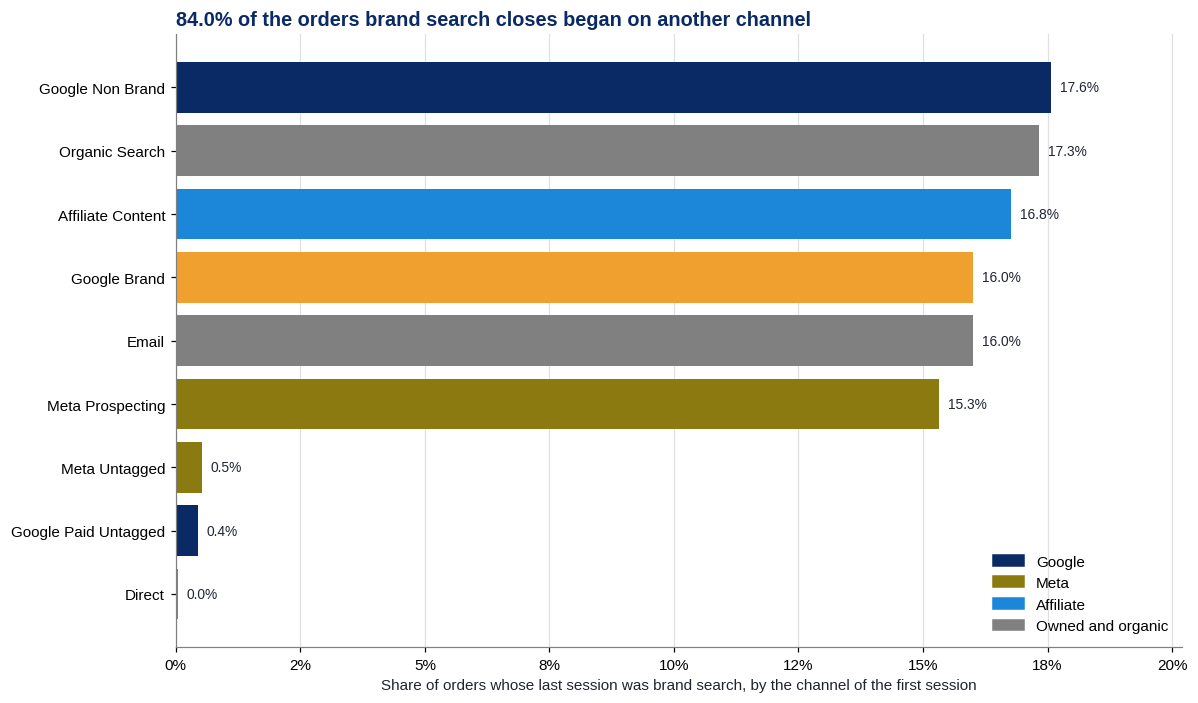

,orders_closed,also_opened,single_session
last_touch_channel,,,
Meta Retargeting,"1,887",12.2%,12.2%
Google Brand,"2,499",16.0%,16.0%
Affiliate Coupon,"1,609",20.9%,20.9%
Direct,"2,843",29.3%,29.2%
Email,"3,308",34.8%,34.7%
Google Paid Untagged,165,47.9%,47.9%
Meta Untagged,120,52.5%,51.7%
Organic Search,"4,550",55.1%,55.1%
Google Non Brand,"3,562",58.4%,58.4%


In [9]:
# 1. Where journeys that end in brand search begin
brand = j[j['last_touch_channel'] == 'google_brand']
starts_brand = brand['first_touch_channel'].map(LABEL).value_counts()
start_pct = 100 * starts_brand / len(brand)
print(f"{'':<52}{'this notebook':>16}{'from SQL':>16}")
check('orders closed by brand search', len(brand), 2499)
check('  of which single session', (brand['touches_in_journey'] == 1).sum(), starts_brand.get('Google Brand', 0))
show(pd.DataFrame({'orders': starts_brand, 'share_pct': start_pct}), ints=['orders'], pct=['share_pct'])

colours = dict(COLOUR_BY_LABEL)
colours['Google Brand'] = AMBER
own = start_pct.get('Google Brand', 0)
hbar(start_pct, lambda v: f'{v:.1f}%',
     title=f'{100 - own:.1f}% of the orders brand search closes began on another channel',
     xlabel='Share of orders whose last session was brand search, by the channel of the first session',
     colours=colours, axis_fmt='{x:.0f}%', legend=True)

# 2. Every channel: how much of what it closes did it also open
closers = pd.DataFrame({
    'orders_closed' : j.groupby('last_touch_channel').size(),
    'also_opened'   : 100 * (j['first_touch_channel'] == j['last_touch_channel']).groupby(j['last_touch_channel']).mean(),
    'single_session': 100 * (j['touches_in_journey'] == 1).groupby(j['last_touch_channel']).mean()})
closers.index = closers.index.map(LABEL)
show(closers.sort_values('also_opened'), ints=['orders_closed'], pct=['also_opened', 'single_session'])

**Insight and business takeaway:**

84.0 percent of the 2,499 orders brand search closed began on another channel, spread almost evenly: Google Non Brand 17.6 percent, Organic Search 17.3, Affiliate Content 16.8, Email 16.0 and Meta Prospecting 15.3. The other 16.0 percent, 400 orders, began and ended with brand search in a single session: someone typed the shop's name and bought.

On the same scale, Meta Retargeting opened only 12.2 percent of the journeys it closed, Google Brand 16.0, Affiliate Coupon 20.9 and Direct 29.3, while Meta Prospecting opened 78.3 percent, Referral 71.0 and Affiliate Content 64.7. In every row the share also opened is within a point of the single session share. In this data a journey of two or more sessions almost never starts and ends on the same channel.

**Indication:** in the GA4 year brand search mostly closed journeys other channels began. If the three years look like that one, much of its internal ROAS of 14.3, measured over three years, is credit for demand others created. That does not make it a bad buy: the unit economics show it breaks even if only 11.0 percent of its credited customers are genuinely new. The cheapest way to find out is to pause brand search in one market for a few weeks and watch what organic search and direct pick up.

<h2 style="color:#0A2A66; border-bottom:2px solid #F0A02E; padding-bottom:6px; margin-top:36px;">Section 4: Affiliates</h2>

**Step 4.1: Coupon partners against content partners**

The affiliate network pays two kinds of partner in the same way, a share of the order value, but they do different work. A content partner writes something, a reading list or a study guide, and a reader follows a link to buy. A coupon partner lists discount codes, and people looking for a code while they shop find it there.

The table compares commission, how soon the partner click came before the order, how often the order system credits the order to the partner at all, how many orders are a customer's first, order value and refunds. GA4 adds one more test on the orders it saw: whether the session the person bought in had already started before they clicked the partner link. Someone already in their buying session who then goes to a coupon site was most likely buying anyway. The network and GA4 keep separate clocks, so the transactions the order system credits to the partner, where the partner click should have started the session, show how often the clocks disagree.

                                                       this notebook        from SQL
content transactions                                           2,751           2,751   matches
coupon transactions                                           14,593          14,593   matches
coupon clicks within 10 minutes of the order                   69.8%           69.8%   matches
coupon median minutes, click to order                           7.25            7.25   matches


,transactions,commission_standing,within_10_min,median_minutes,credited_to_partner,first_orders,aov_after_refunds,refunded,commission_rate
partner_type,,,,,,,,,
content,"2,751","$45,941.56",2.7%,123.00,100.0%,100.0%,$163.49,3.3%,10.0%
coupon,"14,593","$181,394.58",69.8%,7.25,31.3%,77.9%,$153.17,3.1%,8.0%


coupon on other channels, GA4 saw                              3,728           3,728   matches


transactions_seen session_first  \
partner_type credited_to                                         
content      this partner type               880           104   
coupon       another channel               3,728         3,533   
             this partner type             1,609           174   

                               commission_standing session_first_pct  
partner_type credited_to                                              
content      this partner type          $14,975.05             11.8%  
coupon       another channel            $48,211.68             94.8%  
             this partner type          $18,713.64             10.8%

Session first, coupon on other channels' orders against coupon credited to the partner: +84.0 points, z = 61.1, p = below 1e-300



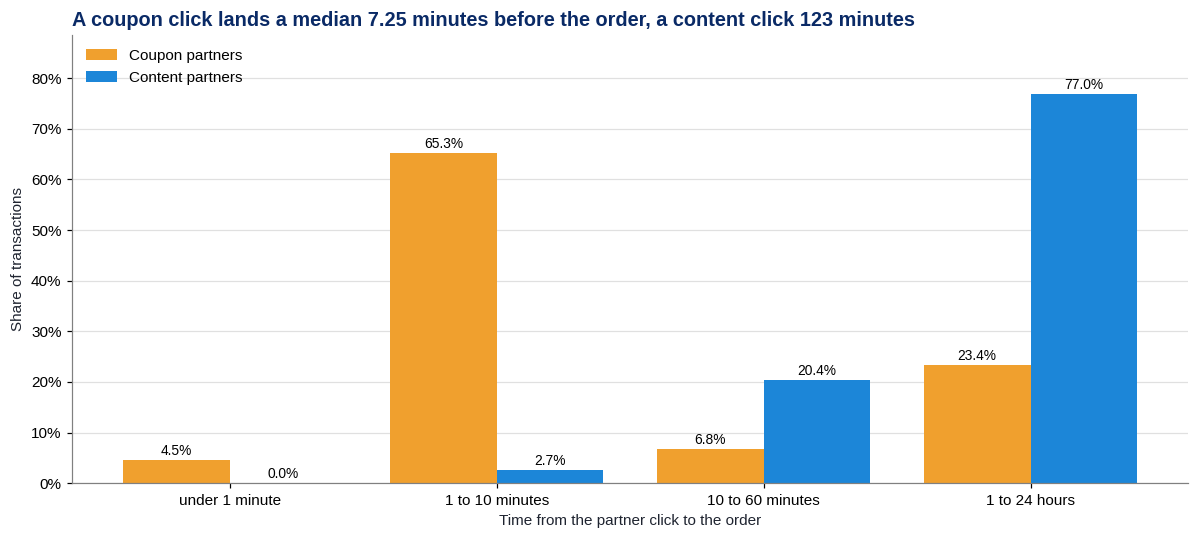

In [10]:
# 1. Side by side
af['within_10_min']    = af['seconds_click_to_order'] < 600
af['credited_to_type'] = af['credited_to'] == 'this partner type'
side = (af.groupby('partner_type')
          .agg(transactions        =('transaction_id', 'size'),
               commission_standing =('commission_standing_usd', 'sum'),
               commission_all      =('commission_usd', 'sum'),
               network_order_value =('network_order_value_usd', 'sum'),
               within_10_min       =('within_10_min', 'mean'),
               median_minutes      =('seconds_click_to_order', lambda s: s.median() / 60),
               credited_to_partner =('credited_to_type', 'mean'),
               first_orders        =('is_first_order', 'mean'),
               aov_after_refunds   =('net_revenue_after_refund_usd', 'mean'),
               refunded            =('order_refunded', 'mean')))
side['commission_rate'] = 100 * side['commission_all'] / side['network_order_value']
for c in ['within_10_min', 'credited_to_partner', 'first_orders', 'refunded']:
    side[c] *= 100

print(f"{'':<52}{'this notebook':>16}{'from SQL':>16}")
check('content transactions', side.loc['content', 'transactions'], 2751)
check('coupon transactions', side.loc['coupon', 'transactions'], 14593)
check('coupon clicks within 10 minutes of the order', side.loc['coupon', 'within_10_min'], 69.8, '{:.1f}%', 1)
check('coupon median minutes, click to order', side.loc['coupon', 'median_minutes'], 7.25, '{:.2f}', 2)
show(side.drop(columns=['commission_all', 'network_order_value']),
     ints=['transactions'], money=['commission_standing', 'aov_after_refunds'],
     pct=['within_10_min', 'credited_to_partner', 'first_orders', 'refunded', 'commission_rate'],
     dec=['median_minutes'])

# 2. On the orders GA4 saw: had the buying session already started before the partner click?
seen_af = af[af['seen_in_ga4']]
prog = (seen_af.groupby(['partner_type', 'credited_to'])
               .agg(transactions_seen  =('transaction_id', 'size'),
                    session_first      =('session_started_before_click', 'sum'),
                    commission_standing=('commission_standing_usd', 'sum')))
prog['session_first_pct'] = 100 * prog['session_first'] / prog['transactions_seen']
check('coupon on other channels, GA4 saw', prog.loc[('coupon', 'another channel'), 'transactions_seen'], 3728)
show(prog, ints=['transactions_seen', 'session_first'], money=['commission_standing'], pct=['session_first_pct'])
a = seen_af[(seen_af['partner_type'] == 'coupon') & (seen_af['credited_to'] == 'another channel')]
b = seen_af[(seen_af['partner_type'] == 'coupon') & (seen_af['credited_to'] == 'this partner type')]
z, p_sf = proportions_ztest([a['session_started_before_click'].sum(), b['session_started_before_click'].sum()],
                            [len(a), len(b)])
print(f"Session first, coupon on other channels' orders against coupon credited to the partner: "
      f"{100 * (a['session_started_before_click'].mean() - b['session_started_before_click'].mean()):+.1f} points, "
      f"z = {z:.1f}, p = {fmt_p(p_sf)}\n")

# 3. Time from partner click to order
bands = (af.groupby(['partner_type', 'click_to_order_band']).size()
           .unstack(fill_value=0).apply(lambda r: 100 * r / r.sum(), axis=1))
labels = [b_.split('. ', 1)[1] for b_ in bands.columns]
x = np.arange(len(labels))
fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(x - 0.2, bands.loc['coupon'], width=0.4, color=AMBER, label='Coupon partners')
ax.bar(x + 0.2, bands.loc['content'], width=0.4, color=BLUE, label='Content partners')
for i, (u, w) in enumerate(zip(bands.loc['coupon'], bands.loc['content'])):
    ax.text(i - 0.2, u + 1, f'{u:.1f}%', ha='center', fontsize=9)
    ax.text(i + 0.2, w + 1, f'{w:.1f}%', ha='center', fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_ylim(0, bands.values.max() * 1.15)
ax.set_xlabel('Time from the partner click to the order')
ax.set_ylabel('Share of transactions')
ax.grid(axis='y', color='#E0E0E0')
ax.set_axisbelow(True)
ax.legend(frameon=False)
ax.set_title(f"A coupon click lands a median {side.loc['coupon', 'median_minutes']:.2f} minutes before the order, "
             f"a content click {side.loc['content', 'median_minutes']:.0f} minutes", loc='left')
plt.tight_layout()
plt.show()

**Insight and business takeaway:**

The two kinds of partner do different work. Content clicks come a median of 123 minutes before the order, and 77.0 percent land between one and 24 hours before; only 2.7 percent are within ten minutes. The order system credits every content transaction to the content partner, every one is a customer's first order, and they average \$163.49 after refunds.

Coupon clicks come a median of 7.25 minutes before the order, 69.8 percent within ten minutes. The order system credits only 31.3 percent of coupon transactions to the coupon partner; another channel won the rest. 77.9 percent are first orders, at \$153.17 after refunds. Coupon partners earn more in total, \$181,394.58 of commission still standing over three years against \$45,941.56, at 8.0 percent of order value against 10.0.

GA4 sharpens the timing. On the 3,728 coupon transactions it saw where another channel won the order, the buying session had already started before the coupon click on 94.8 percent. Where the partner is credited, that happens on 10.8 percent of coupon and 11.8 percent of content transactions, which is roughly how often the network's clock and GA4's disagree. The 84.0 point gap is far beyond noise (z = 61.1).

**Indication:** content partners find new customers and are paid for them. Coupon partners are mostly paid on orders whose buying session had already started before their click.

**Step 4.2: Commission on orders other channels won and on refunded orders, and what new terms would save**

Commission travels with the order it was paid on, so in the clean layer it sits on whichever channel last click credits. That is why every channel's marketing cost on the dashboard is a little above its ad spend. The first table measures it: coupon commission by the channel that won the order. Content commission needs no table, because every content transaction sits on an order credited to content partners.

When an order is refunded, the network rarely reverses the commission: 15 of the 545 transactions on refunded orders were reversed. The usual fix is a validation period: commission is held for some number of days and paid only on orders not refunded by then. The second table shows what each length of hold would have caught.

Two changes to the terms follow, each sized on commission still standing over the three years:

| Change | What it does |
| --- | --- |
| Pay on credit | Pay coupon partners only when the order system credits the order to them, so a code used on an order another channel brought in earns nothing. It needs nothing but the order system to enforce |
| Refund hold | Hold commission for 45 days after the order and drop it if the order is refunded in that time |

                                                       this notebook        from SQL
coupon commission still standing                         $181,394.58     $181,394.58   matches
  on orders another channel won                          $128,942.95     $128,942.95   matches
content commission on orders another channel won               $0.00           $0.00   matches


,transactions,commission,share_pct
order_channel,,,
Affiliate Coupon,"4,569","$52,451.63",28.9%
Organic Search,"1,923","$25,324.83",14.0%
Google Non Brand,"1,557","$20,614.53",11.4%
Meta Prospecting,"1,432","$15,616.97",8.6%
Email,"1,087","$14,789.41",8.2%
Direct,"1,066","$14,237.14",7.8%
Google Brand,997,"$13,449.18",7.4%
Google Shopping,788,"$9,920.27",5.5%
Meta Retargeting,631,"$7,643.73",4.2%


,transactions,commission
status,,
approved,514,"$7,687.06"
pending,16,$216.08
reversed,15,$222.49


transactions still standing on refunded orders                   530             530   matches
  their commission                                         $7,903.14       $7,903.14   matches


,transactions_caught,commission_caught,share_caught_pct
hold_days,,,
14,150,"$2,233.46",28.3%
30,340,"$5,231.63",66.2%
45,530,"$7,903.14",100.0%
60,530,"$7,903.14",100.0%


Refunds on these orders arrived between 4 and 44 days after the order.

both changes together                                    $132,606.99     $132,606.99   matches


,commission_saved,share_of_commission_pct,saved_per_year
change,,,
Pay on credit,"$128,942.95",56.7%,"$42,980.98"
Refund hold,"$7,903.14",3.5%,"$2,634.38"
Both together,"$132,606.99",58.3%,"$44,202.33"


Commission still standing, three years:   $227,336.14
  with both changes:                      $94,729.15  (coupon $50,558.45, content $44,170.70)
Gross profit, three years:                $7,421,060.08
  with the commission saved:              $7,553,667.07  (+1.8%)



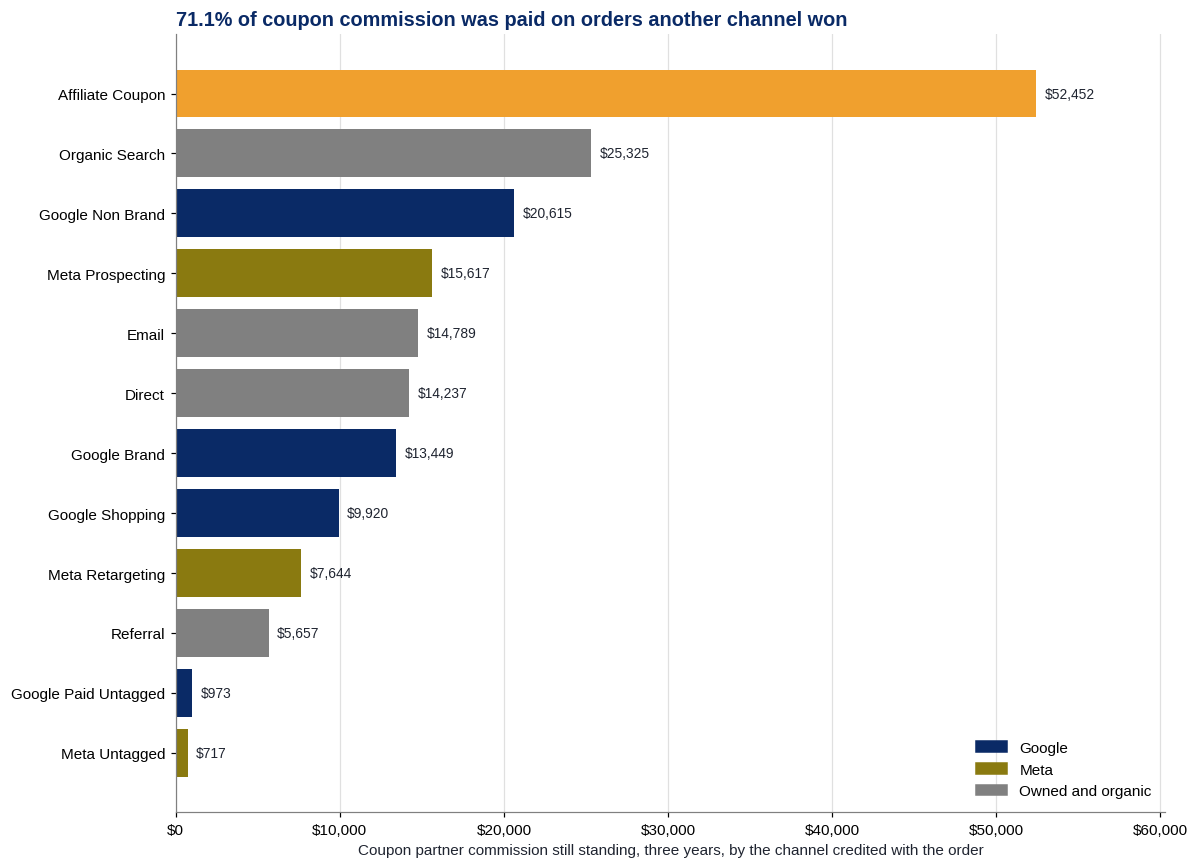

In [11]:
# 1. Coupon commission by the channel that won the order
coupon = af[af['partner_type'] == 'coupon']
by_ch = (coupon.groupby('order_channel')
               .agg(transactions=('transaction_id', 'size'), commission=('commission_standing_usd', 'sum')))
by_ch['share_pct'] = 100 * by_ch['commission'] / by_ch['commission'].sum()
by_ch.index = by_ch.index.map(LABEL)
by_ch = by_ch.sort_values('commission', ascending=False)
other_coupon = by_ch.drop('Affiliate Coupon')['commission'].sum()
total = af['commission_standing_usd'].sum()

print(f"{'':<52}{'this notebook':>16}{'from SQL':>16}")
check('coupon commission still standing', by_ch['commission'].sum(), 181394.58, '${:,.2f}', 2)
check('  on orders another channel won', other_coupon, 128942.95, '${:,.2f}', 2)
check('content commission on orders another channel won',
      af.loc[(af['partner_type'] == 'content') & ~af['credited_to_type'], 'commission_standing_usd'].sum(), 0, '${:,.2f}', 2)
show(by_ch, ints=['transactions'], money=['commission'], pct=['share_pct'])

# 2. Refunded orders: what the network reversed, what still stands, what a hold would catch
refunded = af[af['order_refunded']]
show(refunded.groupby('status').agg(transactions=('transaction_id', 'size'), commission=('commission_usd', 'sum')),
     ints=['transactions'], money=['commission'])
standing = refunded[refunded['status'] != 'reversed']
check('transactions still standing on refunded orders', len(standing), 530)
check('  their commission', standing['commission_standing_usd'].sum(), 7903.14, '${:,.2f}', 2)
holds = pd.DataFrame([{'hold_days': d,
                       'transactions_caught': (standing['days_order_to_refund'] <= d).sum(),
                       'commission_caught': standing.loc[standing['days_order_to_refund'] <= d, 'commission_standing_usd'].sum()}
                      for d in [14, 30, 45, 60]]).set_index('hold_days')
holds['share_caught_pct'] = 100 * holds['commission_caught'] / standing['commission_standing_usd'].sum()
show(holds, ints=['transactions_caught'], money=['commission_caught'], pct=['share_caught_pct'])
print(f"Refunds on these orders arrived between {standing['days_order_to_refund'].min():.0f} and "
      f"{standing['days_order_to_refund'].max():.0f} days after the order.\n")

# 3. The two changes, alone and together
cut = {'Pay on credit': (af['partner_type'] == 'coupon') & ~af['credited_to_type'],
       'Refund hold'  : af['order_refunded']}
cut['Both together'] = cut['Pay on credit'] | cut['Refund hold']
terms = pd.DataFrame([{'change': k, 'commission_saved': af.loc[m, 'commission_standing_usd'].sum()}
                      for k, m in cut.items()]).set_index('change')
terms['share_of_commission_pct'] = 100 * terms['commission_saved'] / total
terms['saved_per_year']          = terms['commission_saved'] / 3
saved = terms.loc['Both together', 'commission_saved']
check('both changes together', saved, 132606.99, '${:,.2f}', 2)
show(terms, money=['commission_saved', 'saved_per_year'], pct=['share_of_commission_pct'])
now  = af.groupby('partner_type')['commission_standing_usd'].sum()
kept = af[~cut['Both together']].groupby('partner_type')['commission_standing_usd'].sum()
print(f"Commission still standing, three years:   ${total:,.2f}")
print(f"  with both changes:                      ${total - saved:,.2f}  "
      f"(coupon ${kept['coupon']:,.2f}, content ${kept['content']:,.2f})")
print(f"Gross profit, three years:                ${7421060.08:,.2f}")
print(f"  with the commission saved:              ${7421060.08 + saved:,.2f}  ({100 * saved / 7421060.08:+.1f}%)\n")

# 4. Coupon commission by the channel that won the order
colours = dict(COLOUR_BY_LABEL)
colours['Affiliate Coupon'] = AMBER
hbar(by_ch['commission'], lambda v: f'${v:,.0f}',
     title=f"{100 * other_coupon / by_ch['commission'].sum():.1f}% of coupon commission was paid on orders another channel won",
     xlabel='Coupon partner commission still standing, three years, by the channel credited with the order',
     colours=colours, axis_fmt='${x:,.0f}', legend=True)

**Insight and business takeaway:**

\$128,942.95 of coupon commission, 71.1 percent of it, was paid on orders the order system credits to another channel. That is 56.7 percent of all commission still standing. It lands on every channel roughly in proportion to its orders: Organic Search carries \$25,325, Google Non Brand \$20,615, Meta Prospecting \$15,617 and Email \$14,789. This is why every channel's marketing cost on the dashboard sits a little above its ad spend.

530 transactions, \$7,903.14 of commission, still stand on orders that were later refunded; the network reversed only 15. Refunds came between 4 and 44 days after the order, so a 30 day hold would have caught 66.2 percent of that commission and a 45 day hold all of it.

Paying coupon partners only on orders credited to them saves \$128,942.95 over three years, and the refund hold \$7,903.14. Together they save \$132,606.99, 58.3 percent of commission, about \$44,202 a year. Commission falls from \$227,336.14 to \$94,729.15, \$50,558.45 to coupon partners and \$44,170.70 to content partners, and gross profit rises 1.8 percent.

**Indication:** both changes are worth putting to the network. Coupon partners keep earning on the 4,569 orders they win by last click unless the order is refunded, content partners' terms barely change, and the business stops paying for codes used on orders another channel won. The risk is coupon partners leaving. The orders at stake are mainly the 4,569 credited to them, whose customers are the least valuable in the base, worth \$81.95 of gross profit in their first year with a 2.5 percent repeat rate. Watch coupon credited orders for a quarter after the change.

<h2 style="color:#0A2A66; border-bottom:2px solid #F0A02E; padding-bottom:6px; margin-top:36px;">Key Findings Summary</h2>

In [12]:
lines = [
    ('Platform ROAS against internal, three years',  f"{tot.loc['both', 'platform_roas']:.2f} against {tot.loc['both', 'internal_roas']:.2f}"),
    ('Claims per order, Google and Meta, median',    f"{g_med:.2f} and {m_med:.2f}"),
    ('Duplicate tag reaching the platforms',         f"{dup_test['flagged_weeks_above_highest'].sum()} flagged weeks above normal"),
    ('Orders claimed, 51 weeks, clicks and views',   f"{claimed:,.1f}"),
    ('  Meta view through',                          f"{-plat.loc[2, 'total_orders']:,.1f}"),
    ('  double counting across the platforms',       f"{-plat.loc[5, 'total_orders']:,.1f}"),
    ('  other channels inside the click window',     f"{-plat.loc[6, 'total_orders']:,.1f}"),
    ('  paid orders that happened',                  f"{actual:,.0f}"),
    ('Share of click window room taken',             f"Google {room.loc['Google', 'share_of_room_taken']:.1f}%, Meta {room.loc['Meta', 'share_of_room_taken']:.1f}%"),
    ('Internal ROAS, 51 weeks',                      f"{both['net revenue, after refunds']:.2f}"),
    ('GA4 capture rate, paid orders',                f"{cap.loc['Both', 'capture_rate']:.3f}"),
    ('Single session journeys',                      f"{dist['share_pct'].iloc[0]:.1f}%"),
    ('Biggest gain under first click',               f"{gainer} {cred.loc[gainer, 'first_vs_last_pct']:+.1f}%"),
    ('Biggest loss under first click',               f"{loser} {cred.loc[loser, 'first_vs_last_pct']:+.1f}%"),
    ('Google Brand ROAS, last click to position',    f"{ret.loc['Google Brand', 'ROAS, last click']:.2f} to {ret.loc['Google Brand', 'ROAS, position based']:.2f}"),
    ('Brand search orders begun elsewhere',          f"{100 - own:.1f}%"),
    ('Coupon clicks within 10 minutes',              f"{side.loc['coupon', 'within_10_min']:.1f}%"),
    ('Coupon on other channels, session first',      f"{prog.loc[('coupon', 'another channel'), 'session_first_pct']:.1f}%"),
    ('Coupon commission on other channels\' orders',  f"${other_coupon:,.2f} ({100 * other_coupon / total:.1f}% of all)"),
    ('Commission on refunded orders',                f"${standing['commission_standing_usd'].sum():,.2f}"),
    ('Saved by both changes, three years',           f"${saved:,.2f}"),
]
print('Reconciliation and attribution, Routledge Direct\n')
for k_, v_ in lines:
    print(f'  {k_:<46}{v_}')

Reconciliation and attribution, Routledge Direct

  Platform ROAS against internal, three years   5.66 against 4.70
  Claims per order, Google and Meta, median     1.23 and 1.22
  Duplicate tag reaching the platforms          0 flagged weeks above normal
  Orders claimed, 51 weeks, clicks and views    21,100.6
    Meta view through                           2,350.2
    double counting across the platforms        800.9
    other channels inside the click window      2,669.5
    paid orders that happened                   15,280
  Share of click window room taken              Google 45.4%, Meta 44.4%
  Internal ROAS, 51 weeks                       4.83
  GA4 capture rate, paid orders                 0.881
  Single session journeys                       46.2%
  Biggest gain under first click                Affiliate Content +190.9%
  Biggest loss under first click                Meta Retargeting -87.7%
  Google Brand ROAS, last click to position     14.80 to 8.66
  Brand search orders beg

<div style="background-color:#FDF4E4; border-left:5px solid #F0A02E; padding:20px; border-radius:6px; margin-top:36px;">
  <h2 style="margin-top:0; color:#0A2A66;">Reconciliation and Attribution: What It Means</h2>
  <p style="color:#1F2430; font-size:1.05em; line-height:1.6;">The numbers disagree for reasons that can be sized. Over the 51 weeks of the GA4 year Google and Meta claimed 21,101 orders and 15,280 happened. Meta's view through purchases account for 2,350 of the difference, orders an unpaid channel won inside a click window for 2,670, and double counting between the two platforms for 801. Every claimed order fits inside what the click windows allow, and the January and February duplicates do not look like they reached the platforms. GA4 sees 88.1 percent of paid orders, with no real difference between Google (88.4) and Meta (87.6). Internal ROAS, net revenue after refunds credited by last click, is the number the budget is built on: 4.83 for these weeks, against 5.83 reported by the platforms.</p>
  <p style="color:#1F2430; font-size:1.05em; line-height:1.6;">Last click favours the channels that finish journeys. Under position based, Google Brand's return falls from 14.80 to 8.66 and Meta Retargeting's halves, while Meta Prospecting rises from 2.68 to 4.14 and Affiliate Content's credit doubles. 84.0 percent of brand search orders began on another channel. These shifts in order credit are far too large to be chance in which of the year's orders were sampled, so the choice of rule is a business decision, and the budget planner should show last click and position based side by side.</p>
  <p style="color:#1F2430; font-size:1.05em; line-height:1.6; margin-bottom:0;">71.1 percent of coupon partners' commission sits on orders other channels won, and on 94.8 percent of those that GA4 saw, the buying session had started before the coupon click. Paying them only on orders credited to them, and holding commission for 45 days and dropping it on orders refunded in that time, would have saved <span>&#36;</span>132,606.99 over three years. Content partners would lose only the <span>&#36;</span>1,770.86 paid on their refunded orders. None of this measures whether a channel creates sales that would not have happened anyway. That needs a holdout test, and pausing brand search in one market is the cheapest place to start.</p>
</div>